# Sesgos inductivos: ¿cuándo importa la arquitectura?

**Redes de Neuronas · Máster Universitario en Inteligencia Artificial Aplicada · Universidad Carlos III de Madrid**

Alejandro Riego Velasco · Javier Aceituno Monja · Santiago Herron Mulet · Rodrigo Toldos Frutos

MLP, CNN, LSTM y Transformer incorporan supuestos distintos sobre la estructura de los datos: ninguno, localidad y pesos compartidos, orden secuencial, y relaciones entre todos los elementos. En este notebook comprobamos con experimentos cuándo esos sesgos ayudan, cuándo perjudican y por qué, sobre Fashion-MNIST, con cuatro modelos de unos 100 000 parámetros entrenados con el mismo protocolo y cinco semillas.

*Declaración de uso de IA: Durante la realización de esta actividad, se ha utilizado Claude (Anthropic) como apoyo en la programación, el análisis y la redacción.*

## Cómo ejecutar este notebook

1. Copiar junto al notebook la carpeta `results/` que lo acompaña (CSV con cada ejecución y checkpoints de la semilla 0 a 4). Con ella, el modo por defecto, `"cargar"`, reproduce todas las tablas, figuras y explicaciones en unos minutos y sin entrenar.
2. Elegir el modo en la celda de configuración:
   - `"cargar"` (por defecto): no entrena; lee los CSV y checkpoints de `results/` y genera tablas y figuras.
   - `"completo"`: entrena todo lo que falte y guarda cada ejecución en `results/`. Si una ejecución ya está en los CSV, se salta, así que se puede interrumpir y relanzar. Desde cero son unos 360 entrenamientos: del orden de un día en un portátil con Apple Silicon (MPS) o en una GPU T4 de Colab.
   - `"prueba"`: el mismo código con un presupuesto mínimo, para comprobar en minutos que todo funciona. Sus números no valen como resultados.
3. *Reiniciar y ejecutar todo.* En Colab conviene *Entorno de ejecución → Cambiar tipo de entorno → GPU (T4)*; también funciona en CPU, más despacio.

**Dónde se obtuvieron los resultados.** Los CSV de `results/` se generaron con este mismo código en un Mac con Apple Silicon (MPS, torch 2.14.1). Con otro dispositivo o versión de PyTorch las operaciones en coma flotante no son idénticas, así que un reentrenamiento da resultados equivalentes en distribución (mismas medias dentro de su σ), no idénticos bit a bit.

**Datos.** Fashion-MNIST (Xiao, Rasul y Vollgraf, 2017), https://github.com/zalandoresearch/fashion-mnist. Se descarga automáticamente con `torchvision.datasets.FashionMNIST`.

**Reproducibilidad.** Semillas fijas para la partición (2026), las permutaciones (777), los subconjuntos (31 y 11), las etiquetas aleatorias (12) y el entrenamiento (0 a 4). Las librerías y versiones se imprimen en la celda siguiente; `requirements.txt` recoge las usadas.

**Mapa del código.** La sección 1 escribe el paquete `sesgos` con `%%writefile` (celdas plegadas: se despliegan con un clic). Qué hay en cada módulo:

| Módulo | Contenido |
|---|---|
| `config.py` | Protocolo común: semillas, partición, presupuesto, rejilla de learning rate, condiciones de cada hipótesis, colores |
| `data.py` | Descarga de Fashion-MNIST, partición estratificada, normalización |
| `transforms.py` | Permutaciones de píxeles y de bloques, traslación, rotación, etiquetas aleatorias |
| `models.py` | MLP, CNN, LSTM y Transformer, y recuento de parámetros |
| `train.py` | Entrenamiento por pasos (H1-H3) y por épocas hasta memorizar (H4), semillas, evaluación |
| `experiments.py` | Cada experimento: barrido de learning rate, H1-H4, controles, E1 y E2; guarda cada ejecución en CSV |
| `explain.py` | Integrated Gradients, atención del Transformer, pesos de la primera capa |
| `stats.py` | Media ± σ, intervalos de Welch y tablas |
| `figures.py` | Todas las figuras, del notebook y del póster |
| `verdicts.py` | Predicciones previas y veredictos observados, con sus criterios |

In [1]:
RUN_MODE = "cargar"          # "cargar" | "completo" | "prueba"
ONLY_MODELS = None           # p. ej. ["cnn"] para entrenar solo un modelo (reparto del cómputo)
ONLY_SEEDS = None            # p. ej. [0, 1, 2]
RESULTS = "results"          # carpeta de resultados (CSV + checkpoints)
DATA = "data"
USE_DRIVE = False            # en Colab: True para guardar los resultados en Google Drive
DRIVE_RESULTS = "/content/drive/MyDrive/RDN - Proyecto de Programación/results"

import os, sys, importlib, platform, warnings
warnings.filterwarnings("ignore", message=".*weights_only.*")      # aviso de torch.load; los checkpoints son nuestros
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    RESULTS = DRIVE_RESULTS
import torch, torchvision, numpy as np, pandas as pd, matplotlib
import scipy
print(f"Python {platform.python_version()} · torch {torch.__version__} · torchvision {torchvision.__version__} · "
      f"numpy {np.__version__} · pandas {pd.__version__} · scipy {scipy.__version__} · matplotlib {matplotlib.__version__}")

Python 3.13.16 · torch 2.14.1+cu130 · torchvision 0.29.1+cu130 · numpy 2.5.3 · pandas 3.0.5 · scipy 1.18.1 · matplotlib 3.11.2


## 1. Código común

Todo el proyecto usa un único paquete, `sesgos`. Las celdas siguientes escriben sus módulos en disco y después se importan. El protocolo completo está en `config.py`: cualquier cambio afecta igual a los cuatro modelos.

In [2]:
import os
os.makedirs("sesgos", exist_ok=True)

In [3]:
%%writefile sesgos/__init__.py
"""Sesgos inductivos: ¿cuándo importa la arquitectura? (Redes de Neuronas, UC3M)."""

Writing sesgos/__init__.py


In [4]:
%%writefile sesgos/config.py
"""Protocolo experimental congelado. Cualquier cambio aquí afecta a los cuatro modelos por igual."""

MODELS = ["mlp", "cnn", "lstm", "vit"]
MODEL_LABELS = {"mlp": "MLP", "cnn": "CNN", "lstm": "LSTM", "vit": "Transformer"}

# Datos
N_VAL = 5000                 # validación sacada del train oficial (estratificada)
SPLIT_SEED = 2026            # semilla de la partición train/val
NORM_FROM = "train"          # media y desviación calculadas solo con train

# Entrenamiento común (baseline, H1, H2)
SEEDS = [0, 1, 2, 3, 4]
BATCH = 128
MAX_STEPS = 8000             # unas 19 épocas sobre 55 000 imágenes
WARMUP = 200
EVAL_EVERY = 250
WEIGHT_DECAY = 0.01          # AdamW por defecto, igual para todos
LR_GRID = [3e-4, 1e-3, 3e-3]
LR_SWEEP_SEED = 0
PATIENCE_EVALS = 0           # sin early stopping: todos entrenan MAX_STEPS y se queda el mejor checkpoint de validación
# Versión del protocolo. v1 usaba early stopping (8 evaluaciones sin mejora) y cortaba algunas ejecuciones de la
# CNN con entrada permutada en la fase ruidosa del principio; v2 entrena siempre los mismos pasos. Los resultados
# de cada versión van a ficheros distintos, así que nunca se mezclan.
PROTOCOL = "v2"

# Procesos en paralelo (Mac con MPS o GPU): tras el barrido de lr se lanzan trabajadores que se reparten las
# ejecuciones pendientes mediante ficheros de bloqueo. 0 = todo en un proceso.
PARALLEL_WORKERS = [["h4", "--models", "vit"], ["h4", "--models", "cnn,lstm,mlp"], ["h2"]]

# H1: permutaciones fijas (semilla propia, distinta de las de entrenamiento)
PERM_SEED = 777

# H2: tamaños de train (estratificados y anidados)
H2_SIZES = [100, 300, 1000, 3000, 10000]   # 55 000 es el baseline
H2_SUBSET_SEED = 31

# H3: transformaciones solo en test
H3_SHIFTS = [0, 1, 2, 3, 4, 5, 6]
H3_ANGLES = [0, 15, 30, 45, 60, 75, 90]
H3_EXTRA_ANGLES = [180]                    # se analiza aparte: hay prendas casi simétricas

# H4: memorización
H4_N = 5000
H4_SUBSET_SEED = 11
H4_LABEL_SEED = 12
H4_FRACTIONS = [0.0, 0.25, 0.5, 1.0]
H4_WEIGHT_DECAYS = [0.0, 0.1]              # sin y con regularización
H4_MAX_EPOCHS = 300
H4_THRESHOLD = 0.95                        # precisión de train que define "memorizado"
# Controles de H4 (añadidos tras ver los resultados, ver la sección 7 del notebook). Separan el efecto de la
# arquitectura del de la optimización. (modelo, fracción de etiquetas aleatorias, weight decay, learning rate, semillas)
H4_CONTROLS = [("mlp", 1.0, 0.0, 1e-3, [0, 1, 2, 3, 4]),   # ¿el MLP memoriza con un lr menor?
               ("mlp", 1.0, 0.0, 3e-4, [0, 1, 2, 3, 4]),
               ("mlp", 1.0, 0.0, 3e-3, [0, 1, 2, 3, 4]),   # el lr del protocolo, repetido en otro dispositivo
               ("lstm", 1.0, 0.0, 1e-3, [0, 1, 2]),        # mismo lr que el Transformer y el MLP de control
               ("cnn", 1.0, 0.0, 1e-3, [0, 1, 2]),
               ("cnn", 0.5, 0.0, 3e-3, [0, 1, 2])]         # misma condición que H4, midiendo también en modo train
# Comprobaciones de robustez (también añadidas tras los resultados): un learning rate por encima de la rejilla
# para los modelos que eligieron su extremo, y H2 con 100 y 300 imágenes cambiando el subconjunto en cada semilla.
LR_EXTRA = [1e-2]
H2_RESAMPLE_SIZES = [100, 300]
H2_RESAMPLE_MODELS = ["mlp", "cnn"]

# Estilo común de figuras y póster, con la paleta de las diapositivas del grupo (verde oscuro, verde azulado,
# ámbar y morado). Los tres modelos con sesgo pasan el validador de daltonismo (todas las parejas con ΔE >= 10
# en protanopía, deuteranopía y tritanopía); el MLP es la referencia sin sesgo y va en gris oscuro casi neutro,
# siempre con línea discontinua y marcador propio como codificación secundaria.
PALETTE = {"mlp": "#2F3B3A", "cnn": "#0F8A74", "lstm": "#C27612", "vit": "#6A4CA5"}
MARKERS = {"mlp": "o", "cnn": "s", "lstm": "^", "vit": "D"}
LINESTYLES = {"mlp": (0, (4, 2)), "cnn": "-", "lstm": "-", "vit": "-"}
INK = "#1F2A2A"
MUTED = "#5B6B6A"
GRID = "#E3E9E7"
DARK = "#10302F"        # fondo de la cabecera de las diapositivas y del póster
MINT = "#EAF2EF"        # paneles de apoyo


def smoke():
    """Modo de prueba rápida (CPU, minutos): mismo código, presupuesto mínimo. No produce resultados válidos."""
    g = globals()
    g.update(SEEDS=[0], MAX_STEPS=60, EVAL_EVERY=20, WARMUP=10, PATIENCE_EVALS=0, LR_GRID=[1e-3],
             H2_SIZES=[100, 1000], H4_N=500, H4_MAX_EPOCHS=3, H3_SHIFTS=[0, 2, 4], H3_ANGLES=[0, 45, 90])

Writing sesgos/config.py


In [5]:
%%writefile sesgos/data.py
"""Fashion-MNIST, particiones fijas y las cuatro vistas de una misma imagen."""
import gzip, os
import numpy as np
import torch

from . import config as C

CLASSES = ["Camiseta", "Pantalón", "Jersey", "Vestido", "Abrigo",
           "Sandalia", "Camisa", "Zapatilla", "Bolso", "Botín"]
FILES = {"xtr": "train-images-idx3-ubyte.gz", "ytr": "train-labels-idx1-ubyte.gz",
         "xte": "t10k-images-idx3-ubyte.gz", "yte": "t10k-labels-idx1-ubyte.gz"}


def _read_idx(path):
    with gzip.open(path, "rb") as f:
        raw = f.read()
    ndim = raw[3]
    dims = [int.from_bytes(raw[4 + 4 * i: 8 + 4 * i], "big") for i in range(ndim)]
    return np.frombuffer(raw, dtype=np.uint8, offset=4 + 4 * ndim).reshape(dims).copy()


def _find_raw(root):
    for d in [root, os.path.join(root, "FashionMNIST", "raw")]:
        if all(os.path.exists(os.path.join(d, f)) for f in FILES.values()):
            return d
    return None


def load_raw(root="data"):
    """Descarga Fashion-MNIST con torchvision (https://github.com/zalandoresearch/fashion-mnist)
    si no está en `root`, y devuelve los arrays uint8 originales."""
    d = _find_raw(root)
    if d is None:
        from torchvision.datasets import FashionMNIST
        FashionMNIST(root, train=True, download=True)
        FashionMNIST(root, train=False, download=True)
        d = _find_raw(root)
    a = {k: _read_idx(os.path.join(d, f)) for k, f in FILES.items()}
    return a["xtr"], a["ytr"].astype(np.int64), a["xte"], a["yte"].astype(np.int64)


def stratified_val(y, n_val=C.N_VAL, seed=C.SPLIT_SEED):
    rng = np.random.default_rng(seed)
    classes = np.unique(y)
    val = np.concatenate([rng.choice(np.flatnonzero(y == c), n_val // len(classes), replace=False)
                          for c in classes])
    val = np.sort(val)
    return np.setdiff1d(np.arange(len(y)), val), val


def nested_subsets(y, idx, sizes, seed):
    """Subconjuntos estratificados y anidados de `idx`: el pequeño está contenido en el grande."""
    rng = np.random.default_rng(seed)
    classes = np.unique(y)
    order = {c: rng.permutation(idx[y[idx] == c]) for c in classes}
    return {n: np.sort(np.concatenate([order[c][: n // len(classes)] for c in classes])) for n in sizes}


class Data:
    """Contiene todo en el dispositivo como tensores (sin DataLoader: con modelos pequeños es más rápido).

    Las imágenes se guardan en [0, 1] y sin normalizar; `norm` se aplica después de cualquier
    transformación, para que el relleno de traslaciones y rotaciones sea el fondo real (0)."""

    def __init__(self, root="data", device="cpu"):
        xtr, ytr, xte, yte = load_raw(root)
        self.train_idx, self.val_idx = stratified_val(ytr)
        self.y_all = ytr
        to_x = lambda a: torch.from_numpy(a).float().div_(255).unsqueeze(1).to(device)
        to_y = lambda a: torch.from_numpy(a).to(device)
        self.X, self.Y = to_x(xtr), to_y(ytr)
        self.Xte, self.Yte = to_x(xte), to_y(yte)
        tr = self.X[torch.from_numpy(self.train_idx).to(device)]
        self.mean, self.std = tr.mean().item(), tr.std().item()
        self.device = device

    def norm(self, x):
        return (x - self.mean) / self.std

    def subset(self, idx):
        idx_t = torch.from_numpy(np.asarray(idx)).to(self.device)
        return self.X[idx_t], self.Y[idx_t]

    def train(self):
        return self.subset(self.train_idx)

    def val(self):
        return self.subset(self.val_idx)

    def test(self):
        return self.Xte, self.Yte

Writing sesgos/data.py


In [6]:
%%writefile sesgos/transforms.py
"""Perturbaciones de la entrada (H1, H3) y de las etiquetas (H4)."""
import math
import numpy as np
import torch
import torch.nn.functional as F


def pixel_permutation(seed, n=784):
    """Permutación fija de los 784 píxeles."""
    return torch.from_numpy(np.random.default_rng(seed).permutation(n))


def block_permutation(seed, img=28, b=4):
    """Permutación que mueve los 49 bloques b×b enteros sin tocar su interior.
    Devuelve la permutación de píxeles y el orden de bloques (para el control exacto del ViT)."""
    nb = img // b
    order = np.random.default_rng(seed).permutation(nb * nb)
    perm = np.empty(img * img, dtype=np.int64)
    for dst, src in enumerate(order):
        sr, sc = divmod(int(src), nb)
        dr, dc = divmod(dst, nb)
        for i in range(b):
            for j in range(b):
                perm[(dr * b + i) * img + dc * b + j] = (sr * b + i) * img + sc * b + j
    return torch.from_numpy(perm), torch.from_numpy(order)


def apply_perm(x, perm):
    """x: (N,1,28,28). El píxel de salida p toma el valor del píxel de entrada perm[p]."""
    if perm is None:
        return x
    n = x.shape[0]
    return x.reshape(n, -1)[:, perm.to(x.device)].reshape(n, 1, 28, 28)


def shift(x, dx=0, dy=0):
    """Traslación entera; lo que entra es fondo (0). dx > 0 a la derecha, dy > 0 hacia abajo."""
    out = torch.zeros_like(x)
    H, W = x.shape[-2:]
    sy, ty = (slice(0, H - dy), slice(dy, H)) if dy >= 0 else (slice(-dy, H), slice(0, H + dy))
    sx, tx = (slice(0, W - dx), slice(dx, W)) if dx >= 0 else (slice(-dx, W), slice(0, W + dx))
    out[..., ty, tx] = x[..., sy, sx]
    return out


def rotate(x, degrees):
    """Rotación alrededor del centro con interpolación bilineal y fondo 0."""
    if degrees == 0:
        return x
    th = math.radians(degrees)
    A = torch.tensor([[math.cos(th), -math.sin(th), 0.0],
                      [math.sin(th), math.cos(th), 0.0]], device=x.device, dtype=x.dtype)
    grid = F.affine_grid(A.expand(x.shape[0], 2, 3), list(x.shape), align_corners=False)
    return F.grid_sample(x, grid, align_corners=False, padding_mode="zeros")


def randomize_labels(y, frac, seed, n_classes=10):
    """Sustituye una fracción de las etiquetas por una clase uniforme al azar.
    La etiqueta nueva coincide con la real un 10 % de las veces, como en Zhang et al. (2017)."""
    y = np.array(y, copy=True)
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(y), int(round(frac * len(y))), replace=False)
    y[idx] = rng.integers(0, n_classes, len(idx))
    return y

Writing sesgos/transforms.py


In [7]:
%%writefile sesgos/models.py
"""Los cuatro modelos, de unos 100k parámetros cada uno. Todos reciben (N, 1, 28, 28)
y cada uno construye su propia vista: vector, imagen, secuencia de filas o secuencia de parches."""
import torch
import torch.nn as nn


class MLP(nn.Module):
    """Sin sesgo estructural: el orden de los 784 píxeles le es indiferente."""
    def __init__(self, hidden=112):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(784, hidden), nn.ReLU(),
                                 nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, 10))

    @property
    def first_layer(self):
        return self.net[1]

    def forward(self, x):
        return self.net(x)


class CNN(nn.Module):
    """Localidad y pesos compartidos; el global average pooling la acerca a la invariancia a traslaciones."""
    def __init__(self, channels=(32, 64, 136)):
        super().__init__()
        c1, c2, c3 = channels
        block = lambda i, o: [nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU()]
        self.features = nn.Sequential(*block(1, c1), nn.MaxPool2d(2),
                                      *block(c1, c2), nn.MaxPool2d(2),
                                      *block(c2, c3))
        self.head = nn.Linear(c3, 10)

    @property
    def first_layer(self):
        return self.features[0]

    def forward(self, x):
        return self.head(self.features(x).mean(dim=(2, 3)))


class RowLSTM(nn.Module):
    """Orden secuencial: lee la imagen fila a fila (28 pasos de 28 píxeles) con los mismos pesos."""
    def __init__(self, hidden=144):
        super().__init__()
        self.lstm = nn.LSTM(28, hidden, batch_first=True)
        self.head = nn.Linear(hidden, 10)

    def forward(self, x):
        _, (h, _) = self.lstm(x.reshape(x.shape[0], 28, 28))
        return self.head(h[-1])


def patchify(x, p=4):
    """(N,1,28,28) -> (N, 49, 16): parches p×p en orden de lectura."""
    n, g = x.shape[0], 28 // p
    return x.reshape(n, g, p, g, p).permute(0, 1, 3, 2, 4).reshape(n, g * g, p * p)


class ViT(nn.Module):
    """Atención entre todos los parches. Sin posiciones sería equivariante a permutar tokens;
    con posiciones aprendidas, la posición de cada parche se aprende de los datos."""
    def __init__(self, dim=64, depth=3, heads=4, ff=128, patch=4, use_pos=True):
        super().__init__()
        self.patch, self.use_pos = patch, use_pos
        tokens = (28 // patch) ** 2
        self.embed = nn.Linear(patch * patch, dim)
        self.cls = nn.Parameter(torch.zeros(1, 1, dim))
        self.pos = nn.Parameter(torch.randn(1, tokens + 1, dim) * 0.02)
        layer = nn.TransformerEncoderLayer(dim, heads, ff, dropout=0.0, activation="gelu",
                                           batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, depth, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(dim)
        self.head = nn.Linear(dim, 10)

    def tokens(self, x):
        t = self.embed(patchify(x, self.patch))
        t = torch.cat([self.cls.expand(t.shape[0], -1, -1), t], dim=1)
        return t + self.pos if self.use_pos else t

    def forward(self, x):
        return self.head(self.norm(self.encoder(self.tokens(x)))[:, 0])


BUILDERS = {"mlp": MLP, "cnn": CNN, "lstm": RowLSTM, "vit": ViT}


def build(name):
    return BUILDERS[name]()


def n_params(model):
    return sum(p.numel() for p in model.parameters())

Writing sesgos/models.py


In [8]:
%%writefile sesgos/train.py
"""Bucles de entrenamiento comunes. Los cuatro modelos pasan exactamente por el mismo código."""
import math, random, time
import numpy as np
import torch
import torch.nn.functional as F

from . import config as C


def pick_device():
    if torch.cuda.is_available():
        return "cuda"
    if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
        return "mps"
    return "cpu"


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


@torch.no_grad()
def accuracy(model, x, y, prep=None, bs=2000):
    model.eval()
    correct = 0
    for i in range(0, len(x), bs):
        xb = x[i:i + bs]
        if prep is not None:
            xb = prep(xb)
        correct += (model(xb).argmax(1) == y[i:i + bs]).sum().item()
    return correct / len(x)


def _schedule(step, total, warmup):
    return min(1.0, (step + 1) / warmup) * 0.5 * (1 + math.cos(math.pi * min(step, total) / total))


def fit(model, xtr, ytr, xval, yval, prep, lr, seed, steps=None, bs=None,
        wd=None, warmup=None, eval_every=None, patience=None):
    """Entrena por pasos con AdamW y cosine decay, evalúa en validación cada `eval_every` pasos,
    se queda con el mejor checkpoint y para si no mejora en `patience` evaluaciones.

    `prep` convierte un lote de imágenes en [0,1] en la entrada del modelo (permutación + normalización).
    Devuelve un dict con la mejor precisión de validación, el paso en que se alcanzó y el tiempo."""
    steps = C.MAX_STEPS if steps is None else steps
    bs = C.BATCH if bs is None else bs
    wd = C.WEIGHT_DECAY if wd is None else wd
    warmup = C.WARMUP if warmup is None else warmup
    eval_every = C.EVAL_EVERY if eval_every is None else eval_every
    patience = C.PATIENCE_EVALS if patience is None else patience
    gen = torch.Generator().manual_seed(seed)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: _schedule(s, steps, warmup))
    n = len(xtr)
    order, pos = torch.randperm(n, generator=gen), 0
    best, best_step, best_state, stale = -1.0, 0, None, 0
    t0 = time.time()
    step = 0
    for step in range(1, steps + 1):
        if pos + bs > n:
            order, pos = torch.randperm(n, generator=gen), 0
        idx = order[pos:pos + min(bs, n)].to(xtr.device)
        pos += bs
        model.train()
        loss = F.cross_entropy(model(prep(xtr[idx])), ytr[idx])
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
        sched.step()
        if step % eval_every == 0 or step == steps:
            acc = accuracy(model, xval, yval, prep)
            if acc > best:
                best, best_step, stale = acc, step, 0
                best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            else:
                stale += 1
                if patience and stale >= patience:
                    break
    model.load_state_dict(best_state)
    return {"best_val_acc": best, "best_step": best_step, "steps_run": step,
            "seconds": time.time() - t0}


def memorize(model, xtr, ytr, xte, yte, prep, lr, seed, wd, max_epochs=None, bs=None, thresholds=None,
             track_batch=False):
    """H4: entrena por épocas con lr constante y sin early stopping. Registra por época la precisión
    en train (sobre las etiquetas usadas para entrenar, corruptas o no) y en test (etiquetas reales).
    El test se evalúa en todas las épocas hasta la 20 (donde está el pico de Arpit et al.) y después cada 5,
    para no multiplicar el coste; el train se evalúa en todas porque define el tiempo hasta memorizar.
    Devuelve la curva y la primera época en que se supera cada umbral (None si no se alcanza).
    Con track_batch=True registra además la precisión media de los lotes durante la época, en modo train
    (con las estadísticas del propio lote en BatchNorm): sirve para ver si la oscilación de la CNN viene de las
    estadísticas acumuladas de BatchNorm que usa la evaluación."""
    max_epochs = C.H4_MAX_EPOCHS if max_epochs is None else max_epochs
    bs = C.BATCH if bs is None else bs
    thresholds = (0.5, 0.8, C.H4_THRESHOLD) if thresholds is None else thresholds
    gen = torch.Generator().manual_seed(seed)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    curve, first = [], {t: None for t in thresholds}
    t0 = time.time()
    for ep in range(1, max_epochs + 1):
        model.train()
        hits = 0
        for idx in torch.randperm(len(xtr), generator=gen).split(bs):
            idx = idx.to(xtr.device)
            out = model(prep(xtr[idx]))
            loss = F.cross_entropy(out, ytr[idx])
            if track_batch:
                hits += (out.argmax(1) == ytr[idx]).sum().item()
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
        tr = accuracy(model, xtr, ytr, prep)
        stop = tr >= 0.999 or ep == max_epochs
        te = accuracy(model, xte, yte, prep) if (ep <= 20 or ep % 5 == 0 or stop) else None
        row = {"epoch": ep, "train_acc": tr, "test_acc": "" if te is None else te, "seconds": time.time() - t0}
        if track_batch:
            row["train_acc_batch"] = hits / len(xtr)
        curve.append(row)
        for t in thresholds:
            if first[t] is None and tr >= t:
                first[t] = ep
        if stop:
            break
    return curve, first

Writing sesgos/train.py


In [9]:
%%writefile sesgos/experiments.py
"""Experimentos del proyecto. Cada función añade filas a results/raw/<exp>__<modelo>.csv y se salta
las ejecuciones ya hechas, así que se puede repartir el trabajo entre varias personas (cada una con
sus modelos) y relanzar sin repetir nada. El notebook llama a estas mismas funciones."""
import csv, glob, json, os, time
import numpy as np
import pandas as pd
import torch

from . import config as C
from .data import Data, nested_subsets
from .models import build, n_params
from .train import fit, memorize, set_seed, accuracy
from .transforms import pixel_permutation, block_permutation, apply_perm, shift, rotate, randomize_labels


class Store:
    """Resultados en CSV, uno por experimento y modelo, más checkpoints para H3 y la explicabilidad."""

    def __init__(self, root="results"):
        self.root = root
        os.makedirs(os.path.join(root, "raw"), exist_ok=True)
        os.makedirs(os.path.join(root, "checkpoints"), exist_ok=True)

    def path(self, exp, model):
        return os.path.join(self.root, "raw", f"{exp}__{model}__{C.PROTOCOL}.csv")

    def rows(self, exp, model=None):
        pattern = self.path(exp, model or "*")
        frames = [pd.read_csv(p) for p in sorted(glob.glob(pattern)) if os.path.getsize(p) > 0]
        return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

    def done(self, exp, model, **key):
        df = self.rows(exp, model)
        if df.empty:
            return False
        mask = np.ones(len(df), dtype=bool)
        for k, v in key.items():
            if k not in df:
                return False
            mask &= (df[k].astype(str) == str(v)).to_numpy()
        return bool(mask.any())

    def add(self, exp, model, row):
        p = self.path(exp, model)
        new = not os.path.exists(p) or os.path.getsize(p) == 0
        with open(p, "a", newline="") as f:
            w = csv.DictWriter(f, fieldnames=list(row))
            if new:
                w.writeheader()
            w.writerow(row)

    def add_many(self, exp, model, rows):
        for r in rows:
            self.add(exp, model, r)

    def claim(self, exp, model, **key):
        """Reserva una ejecución para este proceso (fichero de bloqueo creado de forma atómica).
        Devuelve False si otro proceso ya la tiene: así varios procesos se reparten el trabajo sin repetir."""
        d = os.path.join(self.root, "locks")
        os.makedirs(d, exist_ok=True)
        name = "__".join([exp, model] + [f"{k}={v}" for k, v in sorted(key.items())] + [C.PROTOCOL])
        try:
            fd = os.open(os.path.join(d, name + ".lock"), os.O_CREAT | os.O_EXCL | os.O_WRONLY)
            os.write(fd, f"{os.getpid()}\n".encode())
            os.close(fd)
            return True
        except FileExistsError:
            return False

    def skip(self, exp, model, **key):
        """True si la ejecución ya está hecha o la está haciendo otro proceso."""
        return self.done(exp, model, **key) or not self.claim(exp, model, **key)

    def ckpt(self, model, condition, seed):
        return os.path.join(self.root, "checkpoints", f"{model}__{condition}__s{seed}__{C.PROTOCOL}.pt")


def _meta(model_name, m, device):
    return {"n_params": n_params(m), "device": device, "torch": torch.__version__, "protocol": C.PROTOCOL,
            "time": time.strftime("%Y-%m-%d %H:%M:%S")}


def _perms():
    perm = pixel_permutation(C.PERM_SEED)
    bperm, order = block_permutation(C.PERM_SEED)
    return {"original": None, "pixeles": perm, "bloques": bperm}, order


def prep_fn(data, perm):
    return lambda x: data.norm(apply_perm(x, perm))


def chosen_lr(store, model):
    df = store.rows("lr", model)
    if df.empty:
        raise RuntimeError(f"Falta el barrido de learning rate de {model}: ejecuta lr_sweep primero.")
    return float(df.sort_values("best_val_acc", ascending=False).iloc[0]["lr"])


def lr_sweep(data, store, models=None, grid=None, seed=None, verbose=True):
    """Mismo barrido pequeño para los cuatro modelos, una semilla, elegido en validación."""
    models, grid = models or C.MODELS, grid or C.LR_GRID
    seed = C.LR_SWEEP_SEED if seed is None else seed
    xtr, ytr = data.train()
    xva, yva = data.val()
    prep = prep_fn(data, None)
    for name in models:
        for lr in grid:
            if store.skip("lr", name, lr=lr):
                continue
            set_seed(seed)
            m = build(name).to(data.device)
            r = fit(m, xtr, ytr, xva, yva, prep, lr=lr, seed=seed)
            store.add("lr", name, {"exp": "lr", "model": name, "lr": lr, "seed": seed, **r,
                                   **_meta(name, m, data.device)})
            if verbose:
                print(f"lr  {name:5s} lr={lr:.0e}  val={r['best_val_acc']:.4f}  ({r['seconds']:.0f} s)")


def baseline_h1(data, store, models=None, seeds=None, conditions=("original", "pixeles", "bloques"),
                verbose=True):
    """Baseline (condición original) y H1 (píxeles o bloques permutados con una permutación fija),
    con el train completo de 55 000 imágenes."""
    models, seeds = models or C.MODELS, C.SEEDS if seeds is None else seeds
    perms, _ = _perms()
    xtr, ytr = data.train()
    xva, yva = data.val()
    xte, yte = data.test()
    for name in models:
        lr = chosen_lr(store, name)
        for cond in conditions:
            prep = prep_fn(data, perms[cond])
            for seed in seeds:
                if store.skip("h1", name, condition=cond, seed=seed):
                    continue
                set_seed(seed)
                m = build(name).to(data.device)
                r = fit(m, xtr, ytr, xva, yva, prep, lr=lr, seed=seed)
                test = accuracy(m, xte, yte, prep)
                torch.save(m.state_dict(), store.ckpt(name, cond, seed))
                store.add("h1", name, {"exp": "h1", "model": name, "condition": cond, "seed": seed,
                                       "n_train": len(xtr), "lr": lr, **r, "test_acc": test,
                                       **_meta(name, m, data.device)})
                if verbose:
                    print(f"h1  {name:5s} {cond:8s} s{seed}  test={test:.4f}  ({r['seconds']:.0f} s)")


def h2(data, store, models=None, seeds=None, sizes=None, verbose=True):
    """Curvas de aprendizaje: subconjuntos estratificados y anidados del train; mismo val y test.
    El tamaño completo (55 000) se toma del baseline."""
    models, seeds, sizes = models or C.MODELS, C.SEEDS if seeds is None else seeds, sizes or C.H2_SIZES
    subsets = nested_subsets(data.y_all, data.train_idx, sizes, C.H2_SUBSET_SEED)
    xva, yva = data.val()
    xte, yte = data.test()
    prep = prep_fn(data, None)
    for name in models:
        lr = chosen_lr(store, name)
        for n in sizes:
            xtr, ytr = data.subset(subsets[n])
            for seed in seeds:
                if store.skip("h2", name, n_train=n, seed=seed):
                    continue
                set_seed(seed)
                m = build(name).to(data.device)
                r = fit(m, xtr, ytr, xva, yva, prep, lr=lr, seed=seed)
                test = accuracy(m, xte, yte, prep)
                store.add("h2", name, {"exp": "h2", "model": name, "n_train": n, "seed": seed, "lr": lr,
                                       **r, "test_acc": test, **_meta(name, m, data.device)})
                if verbose:
                    print(f"h2  {name:5s} n={n:5d} s{seed}  test={test:.4f}  ({r['seconds']:.0f} s)")


def h3(data, store, models=None, seeds=None, verbose=True):
    """Transformaciones solo en test sobre los modelos del baseline (sin reentrenar)."""
    models, seeds = models or C.MODELS, C.SEEDS if seeds is None else seeds
    xte, yte = data.test()
    prep = prep_fn(data, None)
    tests = ([("shift_h", k, lambda x, k=k: shift(x, dx=k)) for k in C.H3_SHIFTS] +
             [("shift_v", k, lambda x, k=k: shift(x, dy=k)) for k in C.H3_SHIFTS] +
             [("rotation", a, lambda x, a=a: rotate(x, a)) for a in C.H3_ANGLES + C.H3_EXTRA_ANGLES])
    for name in models:
        for seed in seeds:
            if store.skip("h3", name, seed=seed):
                continue
            path = store.ckpt(name, "original", seed)
            if not os.path.exists(path):
                raise RuntimeError(f"Falta {path}: ejecuta baseline_h1 de {name} antes que H3.")
            m = build(name).to(data.device)
            m.load_state_dict(torch.load(path, map_location=data.device))
            base = accuracy(m, xte, yte, prep)
            rows = []
            for kind, mag, f in tests:
                acc = accuracy(m, xte, yte, lambda x, f=f: prep(f(x)))
                rows.append({"exp": "h3", "model": name, "seed": seed, "kind": kind,
                             "magnitude": mag, "test_acc": acc, "retention": acc / base})
            store.add_many("h3", name, rows)
            if verbose:
                print(f"h3  {name:5s} s{seed}  base={base:.4f}")


def h4(data, store, models=None, seeds=None, fractions=None,
       weight_decays=None, max_epochs=None, verbose=True):
    """Memorización: 5 000 imágenes con una fracción de etiquetas aleatorizadas; lr del barrido,
    constante; con y sin weight decay. Guarda el resumen y la curva por época."""
    models, seeds = models or C.MODELS, C.SEEDS if seeds is None else seeds
    fractions = C.H4_FRACTIONS if fractions is None else fractions
    weight_decays = C.H4_WEIGHT_DECAYS if weight_decays is None else weight_decays
    max_epochs = C.H4_MAX_EPOCHS if max_epochs is None else max_epochs
    sub = nested_subsets(data.y_all, data.train_idx, [C.H4_N], C.H4_SUBSET_SEED)[C.H4_N]
    xtr, y_clean = data.subset(sub)
    xte, yte = data.test()
    prep = prep_fn(data, None)
    for name in models:
        lr = chosen_lr(store, name)
        for frac in fractions:
            y_noisy = torch.from_numpy(randomize_labels(data.y_all[sub], frac, C.H4_LABEL_SEED)).to(data.device)
            for wd in weight_decays:
                for seed in seeds:
                    if store.skip("h4", name, label_noise=frac, weight_decay=wd, seed=seed):
                        continue
                    set_seed(seed)
                    m = build(name).to(data.device)
                    curve, first = memorize(m, xtr, y_noisy, xte, yte, prep, lr=lr, seed=seed, wd=wd,
                                            max_epochs=max_epochs)
                    key = {"model": name, "label_noise": frac, "weight_decay": wd, "seed": seed}
                    store.add_many("h4curves", name, [{**key, **c} for c in curve])
                    last = curve[-1]
                    store.add("h4", name, {"exp": "h4", **key, "lr": lr, "n_train": len(sub),
                                           "epochs_run": last["epoch"],
                                           **{f"epoch_{int(t * 100)}": (e if e is not None else "")
                                              for t, e in first.items()},
                                           "final_train_acc": last["train_acc"],
                                           "final_test_acc": last["test_acc"],
                                           "best_test_acc": max(c["test_acc"] for c in curve if c["test_acc"] != ""),
                                           "seconds": last["seconds"], **_meta(name, m, data.device)})
                    if verbose:
                        print(f"h4  {name:5s} ruido={frac:.2f} wd={wd} s{seed}  "
                              f"train={last['train_acc']:.3f} ep95={first[C.H4_THRESHOLD]}  ({last['seconds']:.0f} s)")


def h4_control(data, store, controls=None, max_epochs=None, verbose=True):
    """Controles de H4: las mismas 5 000 imágenes y etiquetas, pero con otro learning rate (constante). Sirven para
    comprobar si el MLP que no memoriza y la CNN inestable con weight decay se deben al learning rate y no a la
    arquitectura. Resultados en results/raw/h4ctl y h4ctlcurves."""
    controls = C.H4_CONTROLS if controls is None else controls
    max_epochs = C.H4_MAX_EPOCHS if max_epochs is None else max_epochs
    sub = nested_subsets(data.y_all, data.train_idx, [C.H4_N], C.H4_SUBSET_SEED)[C.H4_N]
    xtr, _ = data.subset(sub)
    xte, yte = data.test()
    prep = prep_fn(data, None)
    for name, frac, wd, lr, seeds in controls:
        y_noisy = torch.from_numpy(randomize_labels(data.y_all[sub], frac, C.H4_LABEL_SEED)).to(data.device)
        for seed in seeds:
            if store.skip("h4ctl", name, label_noise=frac, weight_decay=wd, lr=lr, seed=seed):
                continue
            set_seed(seed)
            m = build(name).to(data.device)
            curve, first = memorize(m, xtr, y_noisy, xte, yte, prep, lr=lr, seed=seed, wd=wd, max_epochs=max_epochs,
                                    track_batch=True)
            key = {"model": name, "label_noise": frac, "weight_decay": wd, "lr": lr, "seed": seed}
            store.add_many("h4ctlcurves", name, [{**key, **c} for c in curve])
            last = curve[-1]
            store.add("h4ctl", name, {"exp": "h4ctl", **key, "n_train": len(sub), "epochs_run": last["epoch"],
                                      **{f"epoch_{int(t * 100)}": (e if e is not None else "") for t, e in first.items()},
                                      "final_train_acc": last["train_acc"], "final_test_acc": last["test_acc"],
                                      "seconds": last["seconds"], **_meta(name, m, data.device)})
            if verbose:
                print(f"h4ctl {name:5s} ruido={frac:.2f} wd={wd} lr={lr:g} s{seed}  train={last['train_acc']:.3f} "
                      f"ep95={first[C.H4_THRESHOLD]}  ({last['seconds']:.0f} s)")


def lr_extra(data, store, models=("mlp", "cnn", "lstm"), grid=None, verbose=True):
    """Un learning rate más allá de la rejilla, para los modelos que eligieron su extremo (3e-3). Se guarda aparte
    (results/raw/lrext) y no cambia el protocolo: solo dice si el extremo de la rejilla limitaba."""
    grid = C.LR_EXTRA if grid is None else grid
    xtr, ytr = data.train()
    xva, yva = data.val()
    prep = prep_fn(data, None)
    for name in models:
        for lr in grid:
            if store.skip("lrext", name, lr=lr):
                continue
            set_seed(C.LR_SWEEP_SEED)
            m = build(name).to(data.device)
            r = fit(m, xtr, ytr, xva, yva, prep, lr=lr, seed=C.LR_SWEEP_SEED)
            store.add("lrext", name, {"exp": "lrext", "model": name, "lr": lr, "seed": C.LR_SWEEP_SEED, **r,
                                      **_meta(name, m, data.device)})
            if verbose:
                print(f"lrext {name:5s} lr={lr:.0e}  val={r['best_val_acc']:.4f}  ({r['seconds']:.0f} s)")


def h2_resample(data, store, models=None, sizes=None, seeds=None, verbose=True):
    """H2 con pocos datos cambiando también el subconjunto en cada semilla (semilla del subconjunto = 31 + semilla),
    para que la desviación entre semillas incluya qué imágenes tocan. Resultados en results/raw/h2rs."""
    models = C.H2_RESAMPLE_MODELS if models is None else models
    sizes = C.H2_RESAMPLE_SIZES if sizes is None else sizes
    seeds = C.SEEDS if seeds is None else seeds
    xva, yva = data.val()
    xte, yte = data.test()
    prep = prep_fn(data, None)
    for name in models:
        lr = chosen_lr(store, name)
        for seed in seeds:
            subsets = nested_subsets(data.y_all, data.train_idx, sizes, C.H2_SUBSET_SEED + seed)
            for n in sizes:
                if store.skip("h2rs", name, n_train=n, seed=seed):
                    continue
                xtr, ytr = data.subset(subsets[n])
                set_seed(seed)
                m = build(name).to(data.device)
                r = fit(m, xtr, ytr, xva, yva, prep, lr=lr, seed=seed)
                test = accuracy(m, xte, yte, prep)
                store.add("h2rs", name, {"exp": "h2rs", "model": name, "n_train": n, "seed": seed,
                                         "subset_seed": C.H2_SUBSET_SEED + seed, "lr": lr, **r, "test_acc": test,
                                         **_meta(name, m, data.device)})
                if verbose:
                    print(f"h2rs {name:5s} n={n:5d} s{seed}  test={test:.4f}  ({r['seconds']:.0f} s)")


# --------------------------------------------------------------- controles exactos (baratos, CPU)
def mlp_equivalence(data, steps=600, seed=1):
    """Control de H1: un MLP entrenado con píxeles permutados y la primera capa inicializada con las
    columnas permutadas sigue exactamente la misma trayectoria que el MLP original. Se hace en float64
    porque en float32 el redondeo distinto de las sumas se amplifica durante el entrenamiento."""
    from .models import MLP
    perm = pixel_permutation(C.PERM_SEED)
    dev = "cpu"
    X, Y = data.train()
    Xv, Yv = data.val()
    X, Y, Xv, Yv = X.to(dev).double(), Y.to(dev), Xv.to(dev).double(), Yv.to(dev)
    norm = lambda x: (x - data.mean) / data.std
    set_seed(seed); a = MLP().double()
    set_seed(seed); b = MLP().double()
    with torch.no_grad():
        b.first_layer.weight.copy_(a.first_layer.weight[:, perm])
    ra = fit(a, X, Y, Xv, Yv, norm, lr=1e-3, seed=seed, steps=steps, eval_every=200, patience=0)
    rb = fit(b, X, Y, Xv, Yv, lambda x: norm(apply_perm(x, perm)), lr=1e-3, seed=seed, steps=steps,
             eval_every=200, patience=0)
    return {"val_original": ra["best_val_acc"], "val_permutado": rb["best_val_acc"],
            "max_diff_primera_capa": (a.first_layer.weight[:, perm] - b.first_layer.weight).abs().max().item(),
            "max_diff_resto": max((pa - pb).abs().max().item()
                                  for pa, pb in zip(list(a.parameters())[2:], list(b.parameters())[2:]))}


def vit_block_equivalence(seed=0, n=256):
    """Control de H1: permutar los bloques 4×4 equivale a permutar las posiciones aprendidas del ViT."""
    from .models import ViT
    bperm, order = block_permutation(C.PERM_SEED)
    perm = pixel_permutation(C.PERM_SEED)
    set_seed(seed); v = ViT().eval()
    w = ViT().eval(); w.load_state_dict(v.state_dict())
    with torch.no_grad():
        w.pos[0, 1:].copy_(v.pos[0, 1 + order])
    x = torch.rand(n, 1, 28, 28)
    with torch.no_grad():
        return {"diff_bloques": (v(x) - w(apply_perm(x, bperm))).abs().max().item(),
                "diff_pixeles": (v(x) - w(apply_perm(x, perm))).abs().max().item()}


# --------------------------------------------------------------- explicabilidad cuantitativa
def _load(store, name, cond, seed, device):
    path = store.ckpt(name, cond, seed)
    if not os.path.exists(path):
        return None
    m = build(name).to(device)
    m.load_state_dict(torch.load(path, map_location=device))
    return m.eval()


def e1_smoothness(data, store, seeds=None, verbose=True):
    """E1: estructura espacial de la primera capa (correlación entre pesos vecinos) en la CNN (filtros 3×3)
    y el MLP (plantillas 28×28). En el MLP entrenado con píxeles permutados se mide antes y después de
    deshacer la permutación. Usa los checkpoints que haya; los resultados se guardan en results/raw/e1."""
    from .explain import neighbor_corr, first_layer_images
    seeds = C.SEEDS if seeds is None else seeds
    inv = torch.argsort(pixel_permutation(C.PERM_SEED))
    for name, conds in [("mlp", ["original", "pixeles"]), ("cnn", ["original", "pixeles", "bloques"])]:
        for cond in conds:
            for seed in seeds:
                if store.done("e1", name, condition=cond, seed=seed):
                    continue
                m = _load(store, name, cond, seed, "cpu")
                if m is None:
                    continue
                row = {"model": name, "condition": cond, "seed": seed,
                       "neighbor_corr": neighbor_corr(first_layer_images(m, name))}
                if name == "mlp" and cond == "pixeles":
                    row["neighbor_corr_despermutado"] = neighbor_corr(first_layer_images(m, name, inverse_perm=inv))
                store.add("e1", name, {"neighbor_corr_despermutado": "", **row})
                if verbose:
                    print("e1", row)


def e2_equivariance(data, store, seeds=None, shifts=range(1, 9), n=300, verbose=True):
    """E2: ¿se mueve la explicación con la prenda? Correlación entre el mapa de Integrated Gradients de la
    imagen desplazada y el mapa original desplazado, sobre las n primeras imágenes de test, para cada
    desplazamiento horizontal y vertical. Modelos del baseline (condición original)."""
    from .explain import ig_equivariance
    seeds = C.SEEDS if seeds is None else seeds
    x, y = data.Xte[:n].cpu(), data.Yte[:n].cpu()
    for name in C.MODELS:
        for seed in seeds:
            if store.done("e2", name, seed=seed):
                continue
            m = _load(store, name, "original", seed, "cpu")
            if m is None:
                continue
            rows = []
            for vertical in [False, True]:
                for k in shifts:
                    r = ig_equivariance(m, data.norm, x, y, k=k, vertical=vertical)
                    rows.append({"model": name, "seed": seed, "direction": "vertical" if vertical else "horizontal",
                                 "shift": k, "corr": float(r.mean()), "n": n})
            store.add_many("e2", name, rows)
            if verbose:
                print("e2", name, seed, [round(r["corr"], 2) for r in rows if r["direction"] == "horizontal"])

Writing sesgos/experiments.py


In [10]:
%%writefile sesgos/explain.py
"""Explicabilidad: filtros y pesos de la primera capa, mapas de saliencia y atención del ViT."""
import torch

from .models import ViT


def saliency(model, x, target=None):
    """|d logit_objetivo / d entrada| por píxel. x: (N,1,28,28) ya preparado para el modelo."""
    model.eval()
    x = x.clone().requires_grad_(True)
    out = model(x)
    target = out.argmax(1) if target is None else target
    out.gather(1, target.view(-1, 1)).sum().backward()
    return x.grad.abs().squeeze(1).detach()


def integrated_gradients(model, x, target, baseline=None, steps=32):
    """Integrated Gradients (Sundararajan et al., 2017) desde una referencia. Por defecto, ceros; con la entrada
    normalizada, la referencia natural es el fondo negro normalizado: baseline=norm(torch.zeros_like(x_crudo))."""
    model.eval()
    baseline = torch.zeros_like(x) if baseline is None else baseline
    total = torch.zeros_like(x)
    for a in torch.linspace(0, 1, steps, device=x.device):
        xi = (baseline + a * (x - baseline)).requires_grad_(True)
        out = model(xi).gather(1, target.view(-1, 1)).sum()
        total += torch.autograd.grad(out, xi)[0]
    return ((x - baseline) * total / steps).squeeze(1).detach()


def first_layer_images(model, name, inverse_perm=None):
    """Pesos de la primera capa como imágenes.
    CNN: los filtros 3×3. MLP: cada fila de la primera matriz como imagen 28×28; con `inverse_perm`
    se deshace la permutación de la entrada para comparar con el MLP original."""
    if name == "cnn":
        return model.first_layer.weight.detach().squeeze(1)            # (32, 3, 3)
    if name == "mlp":
        w = model.first_layer.weight.detach()                            # (112, 784)
        if inverse_perm is not None:
            w = w[:, inverse_perm]
        return w.reshape(-1, 28, 28)
    raise ValueError(name)


@torch.no_grad()
def vit_cls_attention(model: ViT, x):
    """Atención del token CLS sobre los 49 parches en cada bloque (media de cabezas), como (L, N, 7, 7)."""
    model.eval()
    t = model.tokens(x)
    maps = []
    for layer in model.encoder.layers:
        h = layer.norm1(t)
        a, w = layer.self_attn(h, h, h, need_weights=True, average_attn_weights=True)
        t = t + a
        t = t + layer._ff_block(layer.norm2(t))
        maps.append(w[:, 0, 1:].reshape(-1, 7, 7))
    return torch.stack(maps)


def neighbor_corr(w):
    """Correlación entre pesos vecinos (horizontal y vertical) de un conjunto de filtros o plantillas (K, H, W).
    Alta = estructura espacial suave; cerca de 0 = sin estructura espacial."""
    w = w.detach().float().cpu()
    a = torch.cat([w[:, :, :-1].reshape(-1), w[:, :-1, :].reshape(-1)])
    b = torch.cat([w[:, :, 1:].reshape(-1), w[:, 1:, :].reshape(-1)])
    return float(torch.corrcoef(torch.stack([a, b]))[0, 1])


def ig_equivariance(model, norm, x, y, k=4, steps=16, batch=100, vertical=False):
    """¿Se desplaza la explicación con la prenda? Correlación, imagen a imagen, entre el mapa de Integrated
    Gradients de la imagen desplazada k píxeles (a la derecha, o hacia abajo) y el mapa de la original desplazado k píxeles. 1 = la
    explicación se mueve exactamente con la prenda. x: imágenes sin normalizar (N,1,28,28); norm: normalización."""
    from .transforms import shift
    mv = (lambda t: shift(t, dy=k)) if vertical else (lambda t: shift(t, dx=k))
    out = []
    for i in range(0, len(x), batch):
        xb, yb = x[i:i + batch], y[i:i + batch]
        base = norm(torch.zeros_like(xb))                # referencia: imagen en negro (fondo)
        a = integrated_gradients(model, norm(xb), yb, base, steps).unsqueeze(1)
        b = integrated_gradients(model, norm(mv(xb)), yb, base, steps)
        a = mv(a).squeeze(1)                    # mueve el mapa original (relleno con 0 = sin atribución)
        a, b = a.reshape(len(xb), -1), b.reshape(len(xb), -1)
        a, b = a - a.mean(1, keepdim=True), b - b.mean(1, keepdim=True)
        out.append((a * b).sum(1) / (a.norm(dim=1) * b.norm(dim=1) + 1e-12))
    return torch.cat(out)

Writing sesgos/explain.py


In [11]:
%%writefile sesgos/figures.py
"""Figuras con el estilo común del proyecto (notebook y póster). Leen los CSV de results/raw."""
import glob, os
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager

from . import config as C

L = C.MODEL_LABELS
ROOT = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))


def style(context="notebook"):
    """Registra Carlito (assets/fonts) si está y fija el estilo. context="poster" agranda la letra
    para que las figuras, colocadas a su tamaño final en el A0, midan lo mismo que el texto."""
    fams = []
    for f in glob.glob(os.path.join(ROOT, "assets", "fonts", "*.ttf")):
        font_manager.fontManager.addfont(f)
        fams.append(font_manager.FontProperties(fname=f).get_name())
    base = 10.5 if context == "notebook" else 28
    mpl.rcParams.update({
        # Carlito: la misma métrica que Calibri, la letra de las diapositivas del grupo (licencia OFL)
        "font.family": ["Carlito", "DejaVu Sans"] if "Carlito" in fams else ["DejaVu Sans"],
        "svg.fonttype": "none",
        "font.size": base, "axes.titlesize": base * 1.1, "axes.labelsize": base,
        "xtick.labelsize": base * 0.9, "ytick.labelsize": base * 0.9, "legend.fontsize": base * 0.9,
        "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": base * 0.8,
        "text.color": C.INK, "axes.labelcolor": C.INK, "xtick.color": C.MUTED, "ytick.color": C.MUTED,
        "axes.edgecolor": C.MUTED, "axes.linewidth": 0.8 if context == "notebook" else 1.6,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "axes.grid.axis": "y", "grid.color": C.GRID,
        "grid.linewidth": 0.8 if context == "notebook" else 1.6,
        "lines.linewidth": 2 if context == "notebook" else 4,
        "lines.markersize": 6 if context == "notebook" else 13,
        "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 200,
        "savefig.bbox": "tight", "figure.facecolor": "white", "axes.facecolor": "white",
        "pdf.fonttype": 42,
    })
    return context


def save(fig, name, outdir="figures", svg=False):
    os.makedirs(outdir, exist_ok=True)
    fig.savefig(os.path.join(outdir, f"{name}.pdf"))
    fig.savefig(os.path.join(outdir, f"{name}.png"))
    if svg:                                   # el póster (HTML) incrusta las figuras en SVG, con el texto como texto
        fig.savefig(os.path.join(outdir, f"{name}.svg"), transparent=True)


def _agg(df, by, col):
    g = df.groupby(by)[col]
    return g.mean().rename("mean").to_frame().join(g.std(ddof=1).rename("std")).join(g.size().rename("n")).reset_index()


def _seeds_note(df):
    n = _n_seeds(df)
    return f"media ± σ, {n} semilla" + ("s" if n != 1 else "")


def _note_y():
    return -0.22 if mpl.rcParams["font.size"] < 20 else -0.42


def _poster():
    return mpl.rcParams["font.size"] >= 20


def legend_top(fig, ax=None):
    """Leyenda de modelos en una fila, encima de los paneles (línea + marcador de cada modelo).
    En el póster no se dibuja: la clave de colores está una vez, debajo del mensaje principal."""
    if _poster():
        return
    from matplotlib.lines import Line2D
    h = [Line2D([], [], color=C.PALETTE[m], ls=C.LINESTYLES[m], marker=C.MARKERS[m], label=L[m]) for m in C.MODELS]
    if ax is not None:
        ax.legend(handles=h, loc="lower left", bbox_to_anchor=(0.0, 1.02), ncol=4, handlelength=2.6,
                  columnspacing=1.6, borderaxespad=0)
    else:
        fig.legend(handles=h, loc="upper left", bbox_to_anchor=(0.06, 0.99), ncol=4, handlelength=2.6,
                   columnspacing=1.6)


def present(df):
    """Modelos con datos, en el orden fijo del proyecto (el color sigue al modelo, nunca al orden)."""
    have = set(df["model"]) if "model" in df else set()
    return [m for m in C.MODELS if m in have]


def _n_seeds(df):
    return int(df.groupby([c for c in ["model", "condition", "n_train"] if c in df]).size().min())


def param_table(models):
    from .models import build, n_params
    rows = [{"Modelo": L[m], "Parámetros": n_params(build(m))} for m in models]
    return pd.DataFrame(rows)


# ------------------------------------------------------------------- H1
def h1(df, ax=None):
    """Precisión en test por modelo: original, bloques 4x4 permutados y píxeles permutados."""
    conds = [("original", "Original", "o", "full"), ("bloques", "Bloques 4×4 permutados", "o", "left"),
             ("pixeles", "Píxeles permutados", "o", "none")]
    a = _agg(df, ["model", "condition"], "test_acc")
    fig, ax = (ax.figure, ax) if ax is not None else plt.subplots(figsize=(7.2, 3.4))
    ms = present(df)
    for i, m in enumerate(ms[::-1]):
        sub = a[a.model == m].set_index("condition")
        xs = [sub.loc[c, "mean"] * 100 for c, *_ in conds if c in sub.index]
        ax.plot([min(xs), max(xs)], [i, i], color=C.GRID, lw=mpl.rcParams["lines.linewidth"] * 2.5,
                solid_capstyle="round", zorder=1)
        for k, (c, lab, mk, fill) in enumerate(conds):
            if c not in sub.index:
                continue
            r = sub.loc[c]
            ax.errorbar(r["mean"] * 100, i + (k - 1) * 0.12, xerr=r["std"] * 100, fmt=mk,
                        color=C.PALETTE[m], mfc=C.PALETTE[m] if fill == "full" else "white",
                        fillstyle=fill, capsize=3, zorder=3,
                        label=lab if m == ms[0] else None)
    ax.set_yticks(range(len(ms)), [L[m] for m in ms[::-1]])
    ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
    ax.set_xlabel("Precisión en test (%)")
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, handletextpad=0.3, columnspacing=1.2)
    if not _poster():
        ax.text(1.0, _note_y(), _seeds_note(df), transform=ax.transAxes,
                ha="right", color=C.MUTED, fontsize=mpl.rcParams["font.size"] * 0.8)
    return fig


# ------------------------------------------------------------------- H2
def h2(df_h2, df_h1, axes=None):
    """Izquierda: precisión en test frente al tamaño del train (escala log, banda ±σ).
    Derecha: diferencia con el MLP en puntos, emparejando semillas (misma semilla, mismo subconjunto)."""
    full = df_h1[df_h1.condition == "original"].assign(n_train=int(df_h1.n_train.max()))
    df = pd.concat([df_h2, full[df_h2.columns.intersection(full.columns)]], ignore_index=True)
    a = _agg(df, ["model", "n_train"], "test_acc")
    if axes is None:
        fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.9))
    fig = axes[0].figure
    ns = sorted(a.n_train.unique())
    ticks = [f"{int(n):,}".replace(",", " ") if n != 55000 else "55k" for n in ns]
    ticks = [t.replace(" 000", "k") if t.endswith(" 000") else t for t in ticks]
    ax = axes[0]
    for m in present(a):
        s = a[a.model == m].sort_values("n_train")
        x, y, e = s.n_train, s["mean"] * 100, s["std"].fillna(0) * 100
        ax.fill_between(x, y - e, y + e, color=C.PALETTE[m], alpha=0.15, lw=0)
        ax.plot(x, y, color=C.PALETTE[m], ls=C.LINESTYLES[m], marker=C.MARKERS[m], label=L[m])
    ax.set_ylabel("Precisión en test (%)")
    ax.set_title("Precisión")
    ax = axes[1]
    p = df.pivot_table(index=["n_train", "seed"], columns="model", values="test_acc")
    ax.axhline(0, color=C.PALETTE["mlp"], ls=C.LINESTYLES["mlp"], lw=mpl.rcParams["lines.linewidth"] * 0.6)
    ax.text(ns[0], 0.6, "MLP", color=C.PALETTE["mlp"], va="bottom", fontsize=mpl.rcParams["font.size"] * 0.85)
    if "mlp" in p:
        for m in [x for x in present(a) if x != "mlp"]:
            d = ((p[m] - p["mlp"]) * 100).groupby("n_train").agg(["mean", "std"]).dropna(subset=["mean"])
            ax.fill_between(d.index, d["mean"] - d["std"].fillna(0), d["mean"] + d["std"].fillna(0),
                            color=C.PALETTE[m], alpha=0.15, lw=0)
            ax.plot(d.index, d["mean"], color=C.PALETTE[m], ls=C.LINESTYLES[m], marker=C.MARKERS[m])
    ax.set_ylabel("Diferencia con el MLP (puntos)")
    ax.set_title("Ventaja del sesgo")
    for ax in axes:
        ax.set_xscale("log")
        ax.set_xticks(ns, ticks)
        ax.xaxis.set_minor_locator(mpl.ticker.NullLocator())
        ax.set_xlabel("Imágenes de entrenamiento")
    fig.subplots_adjust(top=0.80 if mpl.rcParams["font.size"] < 20 else 0.88,
                        wspace=0.32 if mpl.rcParams["font.size"] < 20 else 0.42)
    legend_top(fig)
    if not _poster():
        axes[1].text(1.0, _note_y(), _seeds_note(df) + " (escala log en N)", transform=axes[1].transAxes,
                     ha="right", color=C.MUTED, fontsize=mpl.rcParams["font.size"] * 0.75)
    return fig


def _direct_labels(ax, a, xcol):
    last = a.sort_values(xcol).groupby("model").tail(1).sort_values("mean")
    ys = list(last["mean"] * 100)
    for i in range(1, len(ys)):                      # separa etiquetas que se pisan
        ys[i] = max(ys[i], ys[i - 1] + 1.2)
    for (_, r), y in zip(last.iterrows(), ys):
        ax.annotate(L[r.model], (r[xcol], r["mean"] * 100), xytext=(8, (y - r["mean"] * 100) * 4),
                    textcoords="offset points", va="center", color=C.INK,
                    fontsize=mpl.rcParams["font.size"] * 0.9)


def crossings(df_h2, df_h1, a="vit", b="mlp"):
    """Punto de cruce entre dos curvas por semilla (interpolación lineal en log N).
    Devuelve los cruces encontrados por semilla; vacío si las curvas no se cruzan."""
    full = df_h1[df_h1.condition == "original"].assign(n_train=int(df_h1.n_train.max()))
    df = pd.concat([df_h2, full[df_h2.columns.intersection(full.columns)]], ignore_index=True)
    out = []
    for seed, g in df.groupby("seed"):
        p = g.pivot_table(index="n_train", columns="model", values="test_acc").sort_index()
        if a not in p or b not in p:
            continue
        d = (p[a] - p[b]).to_numpy()
        n = np.log10(p.index.to_numpy(dtype=float))
        for i in range(len(d) - 1):
            if d[i] == 0 or d[i] * d[i + 1] < 0:
                t = d[i] / (d[i] - d[i + 1]) if d[i] != d[i + 1] else 0
                out.append({"seed": seed, "n_cruce": 10 ** (n[i] + t * (n[i + 1] - n[i]))})
    return pd.DataFrame(out)


# ------------------------------------------------------------------- H3
def h3(df, axes=None):
    """Retención (precisión transformada / precisión original) frente a la magnitud."""
    panels = [("shift_h", "Traslación horizontal", "píxeles"), ("shift_v", "Traslación vertical", "píxeles"),
              ("rotation", "Rotación", "grados")]
    if mpl.rcParams["font.size"] >= 20:
        panels = [(k, t.replace("Traslación ", "Desplaz. "), x) for k, t, x in panels]
    if axes is None:
        fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.6), sharey=True)
    fig = axes[0].figure
    for ax, (kind, title, xl) in zip(axes, panels):
        d = df[(df["kind"] == kind) & ~((kind == "rotation") & (df.magnitude > max(C.H3_ANGLES)))]
        a = _agg(d, ["model", "magnitude"], "retention")
        for m in present(a):
            s = a[a.model == m].sort_values("magnitude")
            x, y, e = s.magnitude, s["mean"] * 100, s["std"].fillna(0) * 100
            ax.fill_between(x, y - e, y + e, color=C.PALETTE[m], alpha=0.15, lw=0)
            ax.plot(x, y, color=C.PALETTE[m], ls=C.LINESTYLES[m], marker=C.MARKERS[m], label=L[m])
        ax.set_title(title)
        ax.set_xlabel(xl)
        ax.set_ylim(0, 105)
        ax.set_xticks([0, 30, 60, 90] if kind == "rotation" else [0, 2, 4, 6])
    axes[0].set_ylabel("Retención de precisión (%)")
    fig.subplots_adjust(top=0.80 if mpl.rcParams["font.size"] < 20 else 0.88)
    legend_top(fig)
    axes[-1].text(1.0, _note_y(), ("" if _poster() else "media ± σ entre semillas; ") + "retención = precisión transformada / original",
                  transform=axes[-1].transAxes, ha="right", color=C.MUTED, fontsize=mpl.rcParams["font.size"] * 0.8)
    return fig


# ------------------------------------------------------------------- H4
def h4(summary, curves, threshold="epoch_95", axes=None, ctl=None):
    """Izquierda: épocas hasta alcanzar el umbral de train frente a la fracción de ruido, con y sin
    weight decay (huecos = no alcanzado en el tope de épocas). Derecha: curvas con 50 % de ruido.
    `ctl` (resultados de h4ctl): añade el MLP con learning rate 10⁻³ y 100 % de etiquetas al azar."""
    if axes is None:
        fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.9))
    fig = axes[0].figure
    ax = axes[0]
    s = summary.copy()
    cap = int(s.epochs_run.max()) if "epochs_run" in s else C.H4_MAX_EPOCHS
    s["ep"] = pd.to_numeric(s[threshold], errors="coerce")
    poster = _poster()
    # Media de las semillas que llegan al umbral (como en la tabla del notebook). Aro: alguna semilla no llega;
    # si no llega ninguna, el punto se dibuja en el tope de épocas.
    wds = [0.0] if poster else [0.0, max(C.H4_WEIGHT_DECAYS)]
    for wd in wds:
        d = s[s.weight_decay == wd]
        g = d.groupby(["model", "label_noise"])["ep"]
        a = pd.DataFrame({"mean": g.mean(), "std": g.std(), "frac": g.apply(lambda x: x.notna().mean())}).reset_index()
        a["mean"] = a["mean"].fillna(cap)
        for m in present(a):
            q = a[a.model == m].sort_values("label_noise")
            e = q["std"].fillna(0)
            yerr = [e, np.minimum(e, cap - q["mean"])]
            ax.errorbar(q.label_noise * 100, q["mean"], yerr=yerr, color=C.PALETTE[m],
                        ls=C.LINESTYLES[m] if wd == 0 else ":", marker=C.MARKERS[m], alpha=1.0 if wd == 0 else 0.45,
                        mfc="white" if wd else C.PALETTE[m], capsize=2, label=f"{L[m]}" if wd == 0 else None)
            hit = q[q.frac < 1]
            ax.scatter(hit.label_noise * 100, hit["mean"], s=(520 if poster else 120), facecolors="none",
                       edgecolors=C.INK, lw=(2.2 if poster else 1), zorder=4)
    ax.axhline(cap, color=C.MUTED, lw=0.8, ls="--")
    if ctl is not None and not ctl.empty:
        q = ctl[(ctl.model == "mlp") & (ctl.label_noise == 1.0) & (ctl.weight_decay == 0.0) & (np.isclose(ctl.lr, 1e-3))]
        ep = pd.to_numeric(q[threshold], errors="coerce").dropna()
        if len(ep):
            ax.errorbar([100], [ep.mean()], yerr=[[ep.std()], [ep.std()]], color=C.PALETTE["mlp"], marker="*",
                        ms=mpl.rcParams["lines.markersize"] * 2.0, ls="none", capsize=2, zorder=5)
            ax.annotate("estrella: MLP con lr 10⁻³", (100, ep.mean()), xytext=(97, 22), textcoords="data",
                        ha="right", va="center", color=C.PALETTE["mlp"], fontsize=mpl.rcParams["font.size"] * 0.8,
                        arrowprops=dict(arrowstyle="-", color=C.PALETTE["mlp"], lw=0.8, shrinkB=6))
    ax.set_xticks([f * 100 for f in C.H4_FRACTIONS])
    ax.set_xlabel("Etiquetas aleatorizadas (%)")
    ax.set_ylabel(f"Épocas hasta {threshold.split('_')[1]} % en train")
    ax.set_title("Ritmo de memorización")
    if poster:
        ax.annotate("aro: el MLP no llega con 3·10⁻³", (100, cap), xytext=(0, cap * 0.97), color=C.INK, va="top",
                    fontsize=mpl.rcParams["font.size"] * 0.85)
    else:
        ax.text(0.0, _note_y(), "Izquierda: continua sin weight decay, punteada con 0,1; media de las semillas que llegan; "
                "aro: alguna no llega en 300 épocas.\n"
                "Derecha: línea fina = train (etiquetas ruidosas), gruesa = test (etiquetas reales), banda = ±σ del test.",
                transform=ax.transAxes, color=C.MUTED, fontsize=mpl.rcParams["font.size"] * 0.8, va="top")
    ax = axes[1]
    c = curves[(curves.label_noise == 0.5) & (curves.weight_decay == 0.0)]
    for m in present(c):
        g = c[c.model == m].assign(test_acc=lambda d: pd.to_numeric(d.test_acc, errors="coerce"))
        # hasta la primera época en que alguna semilla para (tras memorizar): así la media es siempre de todas
        g = g[g.epoch <= g.groupby("seed").epoch.max().min()]
        sd = g.groupby("epoch")["test_acc"].std()
        g = g.groupby("epoch")[["train_acc", "test_acc"]].mean()
        if not poster:
            ax.plot(g.index, g.train_acc * 100, color=C.PALETTE[m], ls=C.LINESTYLES[m], lw=1.4)
        gt = g.test_acc.dropna()
        e = sd.reindex(gt.index).fillna(0)
        ax.fill_between(gt.index, (gt - e) * 100, (gt + e) * 100, color=C.PALETTE[m], alpha=0.15, lw=0)
        ax.plot(gt.index, gt * 100, color=C.PALETTE[m], ls=C.LINESTYLES[m], alpha=1.0 if poster else 0.55,
                lw=mpl.rcParams["lines.linewidth"] * 1.2, label=L[m])
    ax.set_xscale("log")
    ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:g}"))
    ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
    ax.set_xlabel("Época (escala log)")
    ax.set_ylabel("Precisión en test (%)" if poster else "Precisión (%)")
    ax.set_title("Test con 50 % de ruido" if poster else "Con 50 % de ruido")
    fig.subplots_adjust(top=0.80 if mpl.rcParams["font.size"] < 20 else 0.88,
                        wspace=0.32 if mpl.rcParams["font.size"] < 20 else 0.42)
    legend_top(fig)
    return fig


# ------------------------------------------------------------------- explicabilidad
def e2(df, axes=None):
    """E2: correlación entre la explicación (Integrated Gradients) de la imagen desplazada y la explicación
    original desplazada, frente al desplazamiento. 1 = la explicación se mueve con la prenda."""
    if axes is None:
        fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.4), sharey=True)
    fig = axes[0].figure
    a = _agg(df, ["model", "direction", "shift"], "corr")
    for ax, d, t in zip(axes, ["horizontal", "vertical"], ["Horizontal", "Vertical"]):
        for m in present(a):
            q = a[(a.model == m) & (a.direction == d)].sort_values("shift")
            ax.fill_between(q["shift"], q["mean"] - q["std"].fillna(0), q["mean"] + q["std"].fillna(0),
                            color=C.PALETTE[m], alpha=0.15, lw=0)
            ax.plot(q["shift"], q["mean"], color=C.PALETTE[m], ls=C.LINESTYLES[m], marker=C.MARKERS[m])
        ax.axhline(0, color=C.MUTED, lw=0.8)
        ax.set_xticks(sorted(a["shift"].unique()))
        ax.set_xlabel("Desplazamiento (píxeles)")
        ax.set_title(t)
    axes[0].set_ylabel("¿Se mueve la explicación?")
    axes[0].set_ylim(-0.1, 1.0)
    fig.subplots_adjust(top=0.78 if mpl.rcParams["font.size"] < 20 else 0.88,
                        wspace=0.12 if mpl.rcParams["font.size"] < 20 else 0.16)
    legend_top(fig)
    if not _poster():
        axes[1].text(1.0, _note_y(), f"correlación de Integrated Gradients, media ± σ, {df.seed.nunique()} semillas",
                     transform=axes[1].transAxes, ha="right", color=C.MUTED, fontsize=mpl.rcParams["font.size"] * 0.75)
    return fig


def image_grid(imgs, rows, cols, ax_titles=None, cmap="RdBu_r", symmetric=True, figsize=None, title=None,
               row_labels=None, cbar_label=None):
    """Rejilla de imágenes, cada una con su propia escala (simétrica en torno a 0 si `symmetric`).
    `row_labels` rotula cada fila a la izquierda; `cbar_label` añade una barra de color común (escala relativa)."""
    fig, axes = plt.subplots(rows, cols, figsize=figsize or (cols * 0.9 + (0.9 if row_labels else 0),
                                                                 rows * 0.9 + 0.4), squeeze=False)
    im_ = None
    for k, ax in enumerate(axes.ravel()):
        ax.set_xticks([]); ax.set_yticks([])
        for sp in ax.spines.values():
            sp.set_visible(False)
        ax.grid(False)
        if k < len(imgs):
            im = imgs[k]
            v = float(np.abs(im).max()) or 1.0
            im_ = ax.imshow(np.asarray(im) / v, cmap=cmap, vmin=-1 if symmetric else 0, vmax=1, interpolation="nearest")
            if ax_titles:
                ax.set_title(ax_titles[k], fontsize=mpl.rcParams["font.size"] * 0.7, loc="center")
    if row_labels:
        for r, lab in enumerate(row_labels):
            axes[r, 0].set_ylabel(lab, rotation=0, ha="right", va="center", fontsize=mpl.rcParams["font.size"] * 0.8)
    if cbar_label and im_ is not None:
        cb = fig.colorbar(im_, ax=axes.ravel().tolist(), fraction=0.025, pad=0.02)
        cb.set_label(cbar_label, fontsize=mpl.rcParams["font.size"] * 0.75)
        cb.ax.tick_params(labelsize=mpl.rcParams["font.size"] * 0.7)
    if title:
        fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
    return fig


QUESTIONS = {"H1": "¿Cae al\npermutar?", "H2": "¿Supera al MLP\ncon pocos datos?",
             "H3": "¿Tolera la\ntraslación?", "H4": "¿Memoriza antes\nque el MLP?"}


def verdict_matrix(pred, obs, ax=None):
    """Matriz modelos × hipótesis. pred/obs: dict[(modelo, "H1")] -> "si" | "parcial" | "no".
    Dentro de cada celda: izquierda = no, centro = en parte, derecha = sí.
    Círculo hueco = predicción; relleno = resultado."""
    hyps = list(QUESTIONS)
    x_of = {"no": -0.28, "parcial": 0.0, "si": 0.28}
    fig, ax = (ax.figure, ax) if ax is not None else plt.subplots(figsize=(7.4, 3.8))
    big, small = (420, 170) if mpl.rcParams["font.size"] < 20 else (2600, 1050)
    for j, m in enumerate(C.MODELS):
        for i, h in enumerate(hyps):
            for k in x_of.values():
                ax.plot(i + k, j, marker="|", color=C.GRID, ms=big ** 0.5 * 0.5, zorder=1)
            if (m, h) in pred:
                ax.scatter(i + x_of[pred[(m, h)]], j, s=big, facecolors="white", edgecolors=C.PALETTE[m],
                           lw=2, zorder=2)
            if (m, h) in obs:
                ax.scatter(i + x_of[obs[(m, h)]], j, s=small, color=C.PALETTE[m], zorder=3)
    ax.set_xticks(range(4), [f"{h}\n{q}" for h, q in QUESTIONS.items()])
    ax.xaxis.tick_top()
    ax.set_yticks(range(4), [L[m] for m in C.MODELS])
    ax.set_ylim(3.6, -0.6)                              # margen para que no se corten los círculos
    ax.grid(False)
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.tick_params(length=0)
    for i in range(1, 4):
        ax.axvline(i - 0.5, color=C.GRID, lw=1)
    ax.set_xlim(-0.5, 3.5)
    ax.text(0, 1.0, "", transform=ax.transAxes)
    ax.set_xlabel("En cada celda: no · en parte · sí.   Hueco = predicción, relleno = resultado",
                  color=C.MUTED, fontsize=mpl.rcParams["font.size"] * 0.8)
    return fig


# Huecos de cada figura en el póster A0 (ancho y alto en mm). poster/build_poster.py usa los mismos valores.
POSTER_MM = {"h1": (380, 136), "h2": (380, 136), "h3": (380, 128), "h4": (380, 136), "e2_equivarianza": (300, 128),
             "veredictos": (330, 150)}


def all_figures(results="results", outdir="figures"):
    """Genera todas las figuras de resultados: tamaño notebook en figures/ y tamaño final del A0 en
    figures/poster/ (PDF, PNG y SVG), con la letra a la escala del póster."""
    from .experiments import Store
    from .verdicts import PRED, OBS
    st = Store(results)
    h1_, h2_, h3_, h4s_, h4c_, e2_, ctl_ = (st.rows(e) for e in ["h1", "h2", "h3", "h4", "h4curves", "e2", "h4ctl"])
    makers = [("h1", lambda: h1(h1_), not h1_.empty),
              ("h2", lambda: h2(h2_, h1_), not h2_.empty and not h1_.empty),
              ("h3", lambda: h3(h3_), not h3_.empty),
              ("h4", lambda: h4(h4s_, h4c_, ctl=ctl_), not h4s_.empty),
              ("e2_equivarianza", lambda: e2(e2_), not e2_.empty),
              ("veredictos", lambda: verdict_matrix(PRED, OBS), True)]
    mm = 1 / 25.4
    done = []
    for context, sub in [("notebook", ""), ("poster", "poster")]:
        style(context)
        for name, make, ok in makers:
            if not ok:
                continue
            fig = make()
            if context == "poster":
                w, h = POSTER_MM[name]
                fig.set_size_inches(w * mm, h * mm)
            save(fig, name, os.path.join(outdir, sub), svg=context == "poster")
            plt.close(fig)
            done.append(os.path.join(sub, name))
    style("notebook")
    return done

Writing sesgos/figures.py


In [12]:
%%writefile sesgos/verdicts.py
"""Matriz de veredictos del póster. Preguntas por hipótesis:
H1 ¿cae al permutar?  H2 ¿supera al MLP con pocos datos?  H3 ¿tolera la traslación?  H4 ¿memoriza antes que el MLP?
Valores: "si", "parcial", "no". El MLP es la referencia en H2 y H4, así que no tiene celda ahí."""

# Predicción escrita antes de los experimentos (plan del 18 de octubre). No se modifica.
PRED = {("mlp", "H1"): "no", ("cnn", "H1"): "si", ("lstm", "H1"): "si", ("vit", "H1"): "parcial",
        ("cnn", "H2"): "si", ("lstm", "H2"): "parcial", ("vit", "H2"): "no",
        ("mlp", "H3"): "no", ("cnn", "H3"): "si", ("lstm", "H3"): "parcial", ("vit", "H3"): "no",
        ("cnn", "H4"): "no", ("lstm", "H4"): "no", ("vit", "H4"): "no"}

# Observado con las cinco semillas (protocolo v2). Criterios, fijados al rellenar la tabla:
# H1: caída significativa (IC 95 % de Welch por debajo de 0) con píxeles y con bloques = "si"; con una sola = "parcial".
# H2: supera al MLP (IC 95 % por encima de 0) con 100, 300 y 1 000 imágenes = "si"; en alguno de esos tamaños = "parcial".
# H3: retiene al menos el 85 % de su precisión con 4 px en las dos direcciones = "si"; en una sola, o claramente por
#     encima del MLP en las dos (más de 10 puntos, IC por encima de 0) sin llegar al 85 % = "parcial".
# H4: llega al 95 % de train antes que el MLP (sin weight decay, IC por debajo de 0, o el MLP no llega) con 25, 50 y
#     100 % de etiquetas al azar = "si"; solo con alguno = "parcial".
OBS = {("mlp", "H1"): "no", ("cnn", "H1"): "si", ("lstm", "H1"): "si", ("vit", "H1"): "parcial",
       ("cnn", "H2"): "parcial", ("lstm", "H2"): "no", ("vit", "H2"): "no",
       ("mlp", "H3"): "no", ("cnn", "H3"): "si", ("lstm", "H3"): "parcial", ("vit", "H3"): "parcial",
       ("cnn", "H4"): "parcial", ("lstm", "H4"): "parcial", ("vit", "H4"): "si"}

Writing sesgos/verdicts.py


In [13]:
%%writefile sesgos/stats.py
"""Estadística de los resultados: media ± σ, intervalo de confianza al 95 % y comparación de Welch.

Con 5 semillas las comparaciones tienen poca potencia; por eso se informa siempre la diferencia con su
intervalo, no solo el p-valor."""
import numpy as np
import pandas as pd
from scipy import stats as st

from . import config as C


def summary(df, by, col, scale=100.0):
    """Media, desviación típica, n e IC 95 % (t de Student) por grupo."""
    rows = []
    for key, g in df.groupby(by):
        x = pd.to_numeric(g[col], errors="coerce").dropna().to_numpy() * scale
        n = len(x)
        m = x.mean() if n else np.nan
        s = x.std(ddof=1) if n > 1 else np.nan
        h = st.t.ppf(0.975, n - 1) * s / np.sqrt(n) if n > 1 else np.nan
        key = key if isinstance(key, tuple) else (key,)
        rows.append({**dict(zip(by, key)), "media": m, "sigma": s, "n": n, "ic95_inf": m - h, "ic95_sup": m + h})
    return pd.DataFrame(rows)


def _num(v, dec):
    return f"{v:.{dec}f}".replace(".", ",").replace("-", "−")


def pm_table(df, index, columns, col, scale=100.0, dec=1, index_name=None):
    """Tabla legible: «media ± σ» por celda, con los nombres de modelo en español y n semillas al pie."""
    g = df.groupby([index, columns])[col]
    m, s, n = g.mean() * scale, g.std() * scale, g.count()
    cell = {k: f"{_num(m[k], dec)} ± {_num(s[k], dec)}" if n[k] > 1 else _num(m[k], dec) for k in m.index}
    out = pd.Series(cell).unstack()
    rename = lambda v: C.MODEL_LABELS.get(v, v)
    out = out.rename(index=rename, columns=rename)
    order = [C.MODEL_LABELS[x] for x in C.MODELS]
    if set(out.columns) <= set(order):
        out = out[[c for c in order if c in out.columns]]
    if set(out.index) <= set(order):
        out = out.loc[[c for c in order if c in out.index]]
    out.index.name, out.columns.name = index_name or index, None
    return out


def welch(a, b):
    """Diferencia de medias (a - b), su IC 95 % de Welch y el p-valor bilateral."""
    a, b = np.asarray(a, float), np.asarray(b, float)
    a, b = a[~np.isnan(a)], b[~np.isnan(b)]
    if len(a) < 2 or len(b) < 2:
        return {"dif": a.mean() - b.mean() if len(a) and len(b) else np.nan,
                "ic95_inf": np.nan, "ic95_sup": np.nan, "p": np.nan}
    va, vb = a.var(ddof=1) / len(a), b.var(ddof=1) / len(b)
    se = np.sqrt(va + vb)
    d = a.mean() - b.mean()
    if se == 0:
        return {"dif": d, "ic95_inf": d, "ic95_sup": d, "p": 1.0 if d == 0 else 0.0}
    dof = (va + vb) ** 2 / (va ** 2 / (len(a) - 1) + vb ** 2 / (len(b) - 1))
    h = st.t.ppf(0.975, dof) * se
    return {"dif": d, "ic95_inf": d - h, "ic95_sup": d + h, "p": 2 * st.t.sf(abs(d / se), dof)}


def _fmt(rows):
    """Tabla de comparaciones legible: diferencia en puntos, IC 95 % de Welch y p, con coma decimal."""
    out = pd.DataFrame(rows)
    out["diferencia (puntos)"] = out["dif"].map(lambda v: _num(v, 2))
    out["IC 95 %"] = [f"[{_num(a, 2)}, {_num(b, 2)}]" for a, b in zip(out.ic95_inf, out.ic95_sup)]
    out["p"] = out["p"].map(lambda p: "" if pd.isna(p) else (_num(p, 3) if p >= 0.001 else "< 0,001"))
    out = out.drop(columns=["dif", "ic95_inf", "ic95_sup"])
    return out[[c for c in out.columns if c != "p"] + ["p"]]


def h1_tests(h1):
    """Por modelo: caída de precisión (puntos) al permutar píxeles y bloques; y cada modelo frente al MLP."""
    rows = []
    for m in [x for x in C.MODELS if x in set(h1.model)]:
        g = h1[h1.model == m]
        base = g[g.condition == "original"].test_acc * 100
        for cond in ["bloques", "pixeles"]:
            r = welch(g[g.condition == cond].test_acc * 100, base)
            lab = {"bloques": "bloques permutados", "pixeles": "píxeles permutados"}[cond]
            rows.append({"comparación": f"{C.MODEL_LABELS[m]}: {lab} − original", **r})
    for cond in ["original", "pixeles"]:
        ref = h1[(h1.model == "mlp") & (h1.condition == cond)].test_acc * 100
        for m in [x for x in C.MODELS if x != "mlp" and x in set(h1.model)]:
            r = welch(h1[(h1.model == m) & (h1.condition == cond)].test_acc * 100, ref)
            rows.append({"comparación": f"{C.MODEL_LABELS[m]} − MLP ({'píxeles permutados' if cond == 'pixeles' else cond})", **r})
    return _fmt(rows)


def h2_advantage(h2, h1):
    """Ventaja de cada modelo sobre el MLP (puntos) en cada tamaño de train."""
    full = h1[h1.condition == "original"].assign(n_train=int(h1.n_train.max()))
    df = pd.concat([h2, full[h2.columns.intersection(full.columns)]], ignore_index=True)
    rows = []
    for n in sorted(df.n_train.unique()):
        ref = df[(df.model == "mlp") & (df.n_train == n)].test_acc * 100
        for m in [x for x in C.MODELS if x != "mlp" and x in set(df.model)]:
            r = welch(df[(df.model == m) & (df.n_train == n)].test_acc * 100, ref)
            rows.append({"imágenes de train": int(n), "modelo − MLP": C.MODEL_LABELS[m], **r})
    return _fmt(rows)


def h3_tests(h3, magnitude_shift=4, angle=45):
    """Retención (%) de cada modelo frente al MLP en una magnitud fija de cada transformación."""
    rows = []
    names = {"shift_h": f"horizontal {magnitude_shift} px", "shift_v": f"vertical {magnitude_shift} px",
             "rotation": f"rotación {angle}°"}
    for kind, mag in [("shift_h", magnitude_shift), ("shift_v", magnitude_shift), ("rotation", angle)]:
        d = h3[(h3["kind"] == kind) & (h3.magnitude == mag)]
        ref = d[d.model == "mlp"].retention * 100
        for m in [x for x in C.MODELS if x != "mlp" and x in set(d.model)]:
            r = welch(d[d.model == m].retention * 100, ref)
            rows.append({"transformación": names[kind], "modelo − MLP (retención)": C.MODEL_LABELS[m], **r})
    return _fmt(rows)


def h4_table(h4s, threshold="epoch_95"):
    """Épocas hasta el umbral de train por modelo, ruido y weight decay: media ± σ de las semillas que lo
    alcanzan, cuántas lo alcanzan, segundos hasta el umbral y precisión en test (al parar y pico).
    Los segundos son orientativos: se midieron en un Mac (MPS) con tres procesos en paralelo."""
    s = h4s.copy()
    s["ep"] = pd.to_numeric(s[threshold], errors="coerce")
    s["seg"] = s.seconds * s.ep / s.epochs_run          # tiempo hasta el umbral, suponiendo épocas de igual duración
    s["orden"] = s.model.map({m: i for i, m in enumerate(C.MODELS)})
    rows = []
    for (_, m, wd, f), g in s.groupby(["orden", "model", "weight_decay", "label_noise"]):
        ep = g.ep.dropna()
        rows.append({"modelo": C.MODEL_LABELS[m], "weight decay": _num(wd, 1), "etiquetas al azar": f"{f * 100:.0f} %",
                     "épocas hasta el umbral": "no llega" if ep.empty else
                     (_num(ep.mean(), 0) + (f" ± {_num(ep.std(), 0)}" if len(ep) > 1 else "")),
                     "semillas que llegan": f"{len(ep)}/{len(g)}",
                     "segundos hasta el umbral": "—" if ep.empty else _num(g.seg.mean(), 0),
                     "test al parar (%)": _num(g.final_test_acc.mean() * 100, 1),
                     "pico de test (%)": _num(g.best_test_acc.mean() * 100, 1)})
    return pd.DataFrame(rows)


def h4_control_table(ctl, h4s, threshold="epoch_95"):
    """Controles de H4 junto a la ejecución principal con la misma configuración (modelo, ruido, weight decay).
    Las filas del control indican el dispositivo: el protocolo se ejecutó en MPS y los controles en CPU."""
    main = h4s.assign(origen="protocolo")
    ctl = ctl.assign(origen="control")
    keys = ctl[["model", "label_noise", "weight_decay"]].drop_duplicates()
    df = pd.concat([main.merge(keys), ctl], ignore_index=True)
    df["ep"] = pd.to_numeric(df[threshold], errors="coerce")
    df["orden"] = df.model.map({m: i for i, m in enumerate(C.MODELS)})
    rows = []
    for (_, m, f, wd, lr, o), g in df.groupby(["orden", "model", "label_noise", "weight_decay", "lr", "origen"]):
        ep = g.ep.dropna()
        rows.append({"modelo": C.MODEL_LABELS[m], "etiquetas al azar": f"{f * 100:.0f} %", "weight decay": _num(wd, 1),
                     "learning rate": f"{lr:.0e}".replace("e-0", "e-"), "origen": f"{o} ({g.device.iloc[0]})",
                     "épocas hasta el umbral": "no llega" if ep.empty else
                     (_num(ep.mean(), 0) + (f" ± {_num(ep.std(), 0)}" if len(ep) > 1 else "")),
                     "semillas que llegan": f"{len(ep)}/{len(g)}",
                     "train al parar (%)": _num(g.final_train_acc.mean() * 100, 1),
                     "test al parar (%)": _num(g.final_test_acc.mean() * 100, 1)})
    return pd.DataFrame(rows)


def h2_resample_table(h2rs, h2):
    """H2 con pocos datos: subconjunto fijo (protocolo) frente a otro subconjunto por semilla (control).
    La diferencia CNN − MLP se calcula emparejada por semilla, porque ambos modelos ven el mismo subconjunto."""
    rows = []
    for origen, df in [("subconjunto fijo (protocolo)", h2), ("otro subconjunto por semilla (control)", h2rs)]:
        for n in sorted(set(h2rs.n_train)):
            p = df[df.n_train == n].pivot_table(index="seed", columns="model", values="test_acc") * 100
            if not {"mlp", "cnn"} <= set(p.columns):
                continue
            d = (p.cnn - p.mlp).dropna()
            h = st.t.ppf(0.975, len(d) - 1) * d.std(ddof=1) / np.sqrt(len(d))
            pv = 2 * st.t.sf(abs(d.mean() / (d.std(ddof=1) / np.sqrt(len(d)))), len(d) - 1)
            rows.append({"imágenes": n, "origen": origen,
                         "MLP (%)": f"{_num(p.mlp.mean(), 1)} ± {_num(p.mlp.std(), 1)}",
                         "CNN (%)": f"{_num(p.cnn.mean(), 1)} ± {_num(p.cnn.std(), 1)}",
                         "CNN − MLP (puntos)": f"{_num(d.mean(), 2)} ± {_num(d.std(ddof=1), 2)}",
                         "IC 95 % (emparejado)": f"[{_num(d.mean() - h, 2)}, {_num(d.mean() + h, 2)}]",
                         "p": _num(pv, 3) if pv >= 0.001 else "< 0,001",
                         "semillas en que gana la CNN": f"{int((d > 0).sum())}/{len(d)}"})
    return pd.DataFrame(rows)

Writing sesgos/stats.py


In [14]:
for m in [k for k in sys.modules if k == "sesgos" or k.startswith("sesgos.")]:
    del sys.modules[m]
from sesgos import config as C
if RUN_MODE == "prueba":
    C.smoke()
from sesgos import experiments as E, figures as Fg, explain as X, stats as T
from sesgos.data import Data, CLASSES
from sesgos.train import pick_device
from sesgos.models import build, n_params, patchify
from sesgos.transforms import pixel_permutation, block_permutation, apply_perm, shift
import matplotlib.pyplot as plt

DEVICE = pick_device()
TRAIN = RUN_MODE != "cargar"
data = Data(DATA, DEVICE)
store = E.Store(RESULTS)
Fg.style("notebook")
print(f"dispositivo: {DEVICE} · train {len(data.train_idx)} · val {len(data.val_idx)} · test {len(data.Yte)}")

dispositivo: cpu · train 55000 · val 5000 · test 10000


## 2. Datos y las cuatro vistas de una misma imagen

Partición fija: 55 000 imágenes de entrenamiento y 5 000 de validación, estratificadas y sacadas del train oficial, y las 10 000 de test. La normalización usa la media y la desviación del train, y se aplica después de cualquier transformación, para que el relleno sea siempre el fondo real.

Cada modelo recibe la misma imagen y construye su vista: el MLP un vector de 784, la CNN la imagen 28×28, la LSTM una secuencia de 28 filas de 28 píxeles, y el Transformer una secuencia de 49 parches de 4×4.

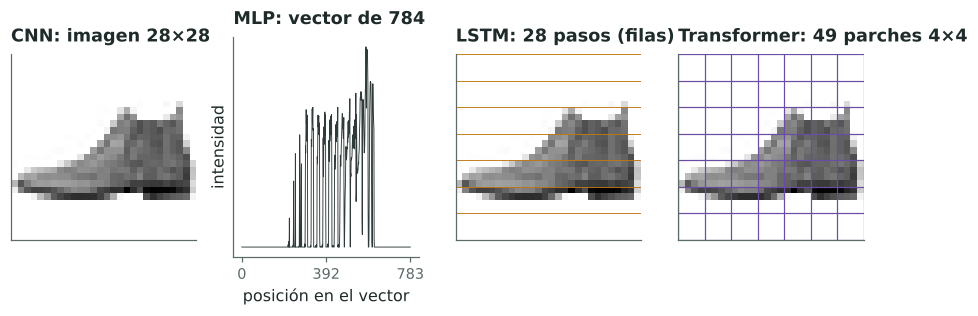

In [15]:
x0 = data.Xte[:1].cpu()
fig, ax = plt.subplots(1, 4, figsize=(10, 2.6))
ax[0].imshow(x0[0, 0], cmap="gray_r"); ax[0].set_title("CNN: imagen 28×28")
ax[1].plot(x0.reshape(-1).numpy(), color=C.PALETTE["mlp"], lw=0.6)
ax[1].set_title("MLP: vector de 784"); ax[1].set_xlabel("posición en el vector")
ax[2].imshow(x0[0, 0], cmap="gray_r")
for r in range(0, 28, 4): ax[2].axhline(r - 0.5, color=C.PALETTE["lstm"], lw=0.6)
ax[2].set_title("LSTM: 28 pasos (filas)")
ax[3].imshow(x0[0, 0], cmap="gray_r")
for r in range(0, 29, 4):
    ax[3].axhline(r - 0.5, color=C.PALETTE["vit"], lw=0.8); ax[3].axvline(r - 0.5, color=C.PALETTE["vit"], lw=0.8)
ax[3].set_title("Transformer: 49 parches 4×4")
for a in ax: a.set_xticks([]); a.set_yticks([]); a.grid(False)
ax[1].set_xticks([0, 392, 783]); ax[1].set_ylabel("intensidad")
plt.show()

## 3. Modelos con número de parámetros comparable

| Modelo | Configuración | Sesgo inductivo |
|---|---|---|
| MLP | 784 → 112 → 112 → 10, ReLU | Ninguno estructural |
| CNN | Conv 3×3 de 32, 64 y 136 canales con BatchNorm, max-pool tras las dos primeras, global average pooling | Localidad y pesos compartidos |
| LSTM | 1 capa, 144 unidades, lee la imagen fila a fila | Orden secuencial |
| Transformer | Parches 4×4 → 64 dimensiones, token CLS, posiciones aprendidas, 3 bloques, 4 cabezas, MLP de 128 | Relaciones entre todos los parches |

**Protocolo común:** AdamW (weight decay 0,01), batch 128, cosine decay con 200 pasos de warmup, como máximo 8 000 pasos, evaluación en validación cada 250 pasos, mejor checkpoint de validación y sin early stopping (todos los modelos entrenan los 8 000 pasos). El learning rate de cada modelo se elige con el mismo barrido {3·10⁻⁴, 10⁻³, 3·10⁻³} en validación. Tres modelos eligieron el extremo superior; un control posterior con 10⁻² (bajo la tabla del barrido) muestra que el MLP y la LSTM no mejorarían y la CNN sí, algo. Sin data augmentation, porque añadiría invariancias que contaminarían H1 y H3.

In [16]:
Fg.param_table(C.MODELS)

,Modelo,Parámetros
0,MLP,101706
1,CNN,99122
2,LSTM,101674
3,Transformer,105546


In [17]:
if TRAIN:
    E.lr_sweep(data, store, models=ONLY_MODELS)
lr = store.rows("lr")
display(T.pm_table(lr, "lr", "model", "best_val_acc", dec=2, index_name="learning rate · precisión en validación (%), semilla 0"))
print("elegido:", {C.MODEL_LABELS[m]: E.chosen_lr(store, m) for m in Fg.present(lr)})
lrx = store.rows("lrext")      # control posterior: un punto más allá de la rejilla (CPU); no cambia el protocolo
if len(lrx):
    display(T.pm_table(lrx, "lr", "model", "best_val_acc", dec=2,
                       index_name="control fuera de la rejilla · precisión en validación (%)"))

,MLP,CNN,LSTM,Transformer
"learning rate · precisión en validación (%), semilla 0",,,,
0.0003,"89,06","90,42","88,76","88,40"
0.0010,"90,24","92,04","90,80","89,46"
0.0030,"90,38","92,92","91,30","89,24"


elegido: {'MLP': 0.003, 'CNN': 0.003, 'LSTM': 0.003, 'Transformer': 0.001}


,MLP,CNN,LSTM
control fuera de la rejilla · precisión en validación (%),,,
0.01,"89,42","93,58","91,22"


## 4. H1 · Estructura de la entrada

> «La ventaja de una arquitectura con sesgo inductivo desaparece si se destruye la estructura de la entrada.»

Aplicamos una permutación fija a todas las imágenes (train, validación y test) y reentrenamos los cuatro modelos. Usamos dos niveles:

- **Píxeles permutados:** se destruye la estructura local y la global.
- **Bloques 4×4 permutados:** se conserva cada bloque intacto y solo cambia dónde está. Separa la estructura local de la global.

**Predicción (escrita antes de los experimentos):** el MLP no cambia con ninguna de las dos, porque permutar la entrada equivale a permutar las columnas de su primera capa. La CNN cae con los píxeles permutados (pierde la localidad) y menos con los bloques. La LSTM cae porque cada paso deja de ser una fila. El Transformer no cambia con los bloques, porque sus posiciones aprendidas absorben esa permutación, y cae algo con los píxeles.

,MLP,CNN,LSTM,Transformer
"precisión en test (%), media ± σ, 5 semillas",,,,
original,"89,27 ± 0,14","91,98 ± 0,16","90,46 ± 0,12","88,38 ± 0,37"
bloques,"89,31 ± 0,17","90,43 ± 0,15","88,57 ± 0,21","88,64 ± 0,24"
pixeles,"89,53 ± 0,20","88,06 ± 0,17","87,66 ± 0,14","86,79 ± 0,28"


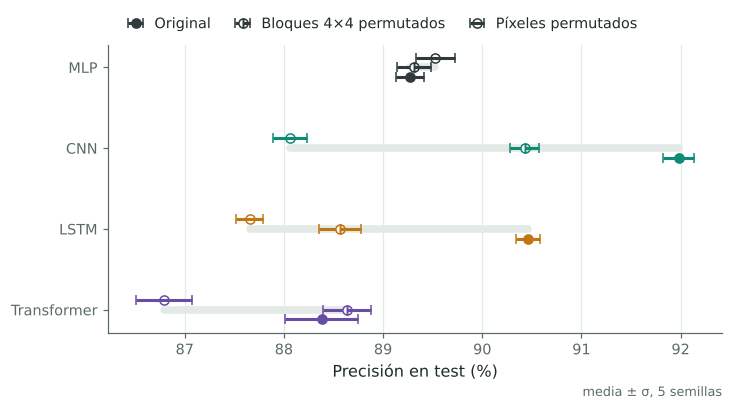

,comparación,diferencia (puntos),IC 95 %,p
0,MLP: bloques permutados − original,"0,04","[−0,19, 0,27]","0,699"
1,MLP: píxeles permutados − original,"0,26","[0,00, 0,51]","0,050"
2,CNN: bloques permutados − original,"−1,55","[−1,78, −1,33]","< 0,001"
3,CNN: píxeles permutados − original,"−3,92","[−4,16, −3,68]","< 0,001"
4,LSTM: bloques permutados − original,"−1,89","[−2,16, −1,63]","< 0,001"
5,LSTM: píxeles permutados − original,"−2,80","[−2,99, −2,61]","< 0,001"
6,Transformer: bloques permutados − original,"0,25","[−0,21, 0,72]","0,238"
7,Transformer: píxeles permutados − original,"−1,59","[−2,07, −1,11]","< 0,001"
8,CNN − MLP (original),"2,71","[2,49, 2,93]","< 0,001"
9,LSTM − MLP (original),"1,19","[0,99, 1,38]","< 0,001"


In [18]:
if TRAIN:
    E.baseline_h1(data, store, models=ONLY_MODELS, seeds=ONLY_SEEDS)
h1 = store.rows("h1")
display(T.pm_table(h1, "condition", "model", "test_acc", dec=2, index_name="precisión en test (%), media ± σ, 5 semillas")
        .reindex(["original", "bloques", "pixeles"]))
fig = Fg.h1(h1); Fg.save(fig, "h1"); plt.show()
display(T.h1_tests(h1))     # diferencias en puntos de precisión, IC 95 % de Welch y p-valor

**Controles exactos.** Dos comprobaciones de que las predicciones exactas no dependen del azar:

- Un MLP entrenado con píxeles permutados, con la primera capa inicializada con las columnas permutadas, sigue la misma trayectoria que el MLP original. Se hace en float64: en float32 el orden distinto de las sumas produce errores de redondeo que el entrenamiento amplifica.
- Permutar los bloques 4×4 equivale a permutar las posiciones aprendidas del Transformer; con los píxeles no hay equivalencia.

In [19]:
print(E.vit_block_equivalence())
if RUN_MODE != "cargar":
    print(E.mlp_equivalence(data, steps=60 if RUN_MODE == "prueba" else 600))

{'diff_bloques': 5.364418029785156e-07, 'diff_pixeles': 0.18867230415344238}


**Resultado: confirmada.** La ventaja de la CNN y de la LSTM desaparece al permutar los píxeles, el MLP no se ve afectado y el Transformer se comporta como se predijo: no nota los bloques y cae algo con los píxeles. Diferencias en puntos de precisión en test, con IC 95 % de Welch y 5 semillas (tabla anterior):

- **MLP.** +0,04 con bloques y +0,26 con píxeles. Lo esperado es exactamente cero: el control en float64 muestra que el MLP con la entrada permutada sigue la misma trayectoria que el original si se permuta igual su primera capa, y la inicialización aleatoria es i.i.d., así que ambos problemas son idénticos en distribución. El p = 0,05 en píxeles es compatible con ruido entre semillas: con 14 comparaciones en la tabla, con la corrección de Holm queda en p ≈ 0,15, no significativo, mientras que las caídas de la CNN, la LSTM y el Transformer con píxeles siguen siéndolo (p < 0,001).
- **CNN.** −3,9 con píxeles y −1,6 con bloques. No solo pierde la ventaja: pasa de superar al MLP por 2,7 puntos a quedar 1,5 por debajo. Sus filtros 3×3 y el pooling suponen que los píxeles vecinos están relacionados; con una permutación ese supuesto es falso y además le limita, porque una capa convolucional no puede combinar libremente píxeles lejanos como hace una capa densa. Con bloques conserva la estructura local dentro de cada bloque de 4×4 y recupera algo más de la mitad de la caída: lo que pierde es la relación entre bloques vecinos que agregan las capas 2 y 3.
- **LSTM.** −2,8 con píxeles y −1,9 con bloques. Cada paso es una fila: la permutación de píxeles convierte cada paso en 28 píxeles sueltos, y la de bloques reordena trozos de 4 píxeles dentro de cada fila y entre filas, así que también rompe la secuencia vertical que aprovecha.
- **Transformer.** Con bloques no cambia (+0,25, no significativo): permutar bloques equivale exactamente a permutar sus posiciones aprendidas (control anterior), y las aprende de nuevo. Con píxeles pierde 1,6: lo que destruye es la coherencia local dentro de cada parche, que es la única estructura espacial que el modelo recibe hecha. Con 55 000 imágenes y 100 000 parámetros, ese sesgo débil no le basta para superar al MLP (−0,9 puntos en el original).

La lectura conjunta: el sesgo ayuda en la medida en que el dato tiene la estructura que el sesgo supone, y cuando no la tiene puede costar más que no tener sesgo. La sección 8 lo muestra en los pesos de la primera capa.

## 5. H2 · Cantidad de datos

> «Cuantos menos datos, más importa el sesgo inductivo.»

Entrenamos con 100, 300, 1 000, 3 000, 10 000 y 55 000 imágenes (subconjuntos estratificados y anidados), con la misma validación y test. El presupuesto es el mismo en todos los tamaños: 8 000 pasos con el learning rate elegido para cada modelo, quedándonos con el mejor checkpoint de validación.

**Predicción:** la CNN por encima en todo el rango, con más ventaja relativa cuanto menos datos. El Transformer el peor con pocos datos, recortando distancia al crecer el conjunto; es improbable que alcance a la CNN con 55 000 imágenes. Los cruces esperables son del Transformer con el MLP y la LSTM.

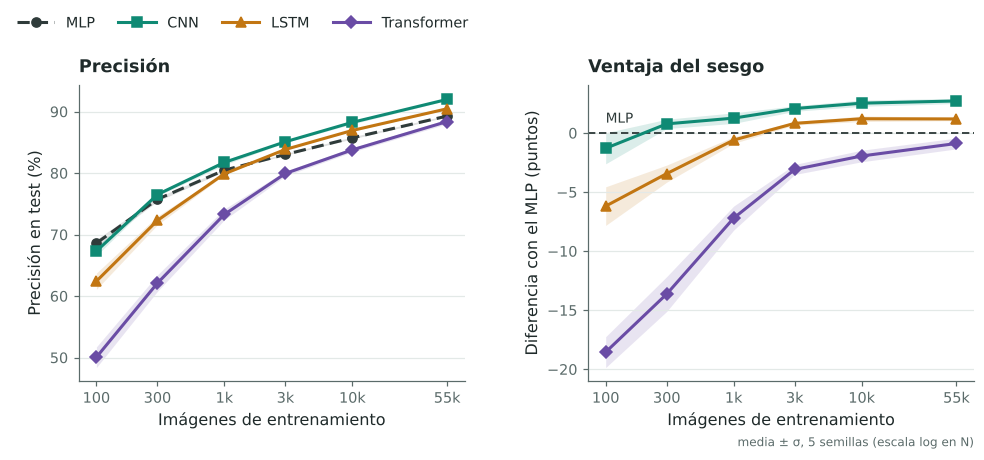

,MLP,CNN,LSTM,Transformer
"imágenes de train · precisión en test (%), media ± σ",,,,
100,"68,6 ± 0,6","67,3 ± 0,7","62,4 ± 1,3","50,1 ± 1,7"
300,"75,7 ± 0,3","76,5 ± 0,2","72,3 ± 0,7","62,1 ± 1,3"
1000,"80,5 ± 0,2","81,7 ± 0,4","79,9 ± 0,2","73,3 ± 0,9"
3000,"83,0 ± 0,1","85,1 ± 0,1","83,8 ± 0,1","79,9 ± 0,4"
10000,"85,7 ± 0,2","88,2 ± 0,3","86,9 ± 0,1","83,8 ± 0,3"
55000,"89,3 ± 0,1","92,0 ± 0,2","90,5 ± 0,1","88,4 ± 0,4"


,imágenes de train,modelo − MLP,diferencia (puntos),IC 95 %,p
0,100,CNN,"−1,30","[−2,28, −0,31]","0,016"
1,100,LSTM,"−6,19","[−7,81, −4,57]","< 0,001"
2,100,Transformer,"−18,55","[−20,59, −16,51]","< 0,001"
3,300,CNN,"0,77","[0,35, 1,20]","0,003"
4,300,LSTM,"−3,44","[−4,30, −2,58]","< 0,001"
5,300,Transformer,"−13,63","[−15,26, −11,99]","< 0,001"
6,1000,CNN,"1,26","[0,78, 1,74]","< 0,001"
7,1000,LSTM,"−0,60","[−0,86, −0,34]","< 0,001"
8,1000,Transformer,"−7,20","[−8,29, −6,12]","< 0,001"
9,3000,CNN,"2,07","[1,88, 2,25]","< 0,001"


vit vs mlp: no se cruzan
vit vs lstm: no se cruzan
cnn vs vit: no se cruzan
lstm vs mlp: cruce en N ≈ 1502 (rango 1301-1890, 5 semillas)
cnn vs mlp: cruce en N ≈ 240 (rango 232-253, 3 semillas)


In [20]:
if TRAIN:
    E.h2(data, store, models=ONLY_MODELS, seeds=ONLY_SEEDS)
h2 = store.rows("h2")
fig = Fg.h2(h2, h1); Fg.save(fig, "h2"); plt.show()
full = h1[h1.condition == "original"].assign(n_train=int(h1.n_train.max()))
display(T.pm_table(pd.concat([h2, full[h2.columns.intersection(full.columns)]]), "n_train", "model", "test_acc",
                   index_name="imágenes de train · precisión en test (%), media ± σ"))
display(T.h2_advantage(h2, h1))   # ventaja sobre el MLP en cada tamaño (puntos, IC 95 % de Welch)
for a_, b_ in [("vit", "mlp"), ("vit", "lstm"), ("cnn", "vit"), ("lstm", "mlp")]:
    c = Fg.crossings(h2, h1, a_, b_)
    print(f"{a_} vs {b_}:", "no se cruzan" if c.empty else
          f"cruce en N ≈ {c.n_cruce.median():.0f} (rango {c.n_cruce.min():.0f}-{c.n_cruce.max():.0f}, {c.seed.nunique()} semillas)")
for a_ in ["cnn"]:
    c = Fg.crossings(h2, h1, a_, "mlp")
    print(f"{a_} vs mlp:", "no se cruzan" if c.empty else
          f"cruce en N ≈ {c.n_cruce.median():.0f} (rango {c.n_cruce.min():.0f}-{c.n_cruce.max():.0f}, {c.seed.nunique()} semillas)")

**Resultado: confirmada, con un matiz importante.** Con pocos datos la arquitectura importa mucho más, pero no por la razón que esperábamos. Precisión media en test y separación entre el mejor y el peor modelo (las σ están en la primera tabla de arriba, entre 0,1 y 1,7 puntos):

| Imágenes | MLP | CNN | LSTM | Transformer | Mejor − peor |
|---|---|---|---|---|---|
| 100 | 68,6 | 67,3 | 62,4 | 50,1 | 18,6 |
| 300 | 75,7 | 76,5 | 72,3 | 62,1 | 14,4 |
| 1 000 | 80,5 | 81,7 | 79,9 | 73,3 | 8,5 |
| 3 000 | 83,0 | 85,1 | 83,8 | 79,9 | 5,2 |
| 10 000 | 85,7 | 88,3 | 86,9 | 83,8 | 4,5 |
| 55 000 | 89,3 | 92,0 | 90,5 | 88,4 | 3,6 |

- **La separación entre arquitecturas crece al bajar los datos**: 18,6 puntos entre el mejor y el peor modelo con 100 imágenes, frente a 3,6 con 55 000. En ese sentido, la hipótesis se cumple.
- **Pero no es el sesgo adecuado el que gana más con pocos datos, sino los sesgos débiles o poco adecuados los que pierden más.** La CNN no supera al MLP con 100 imágenes (−1,3 puntos, IC [−2,3, −0,3]; empata en dos semillas y pierde unos 2 puntos en tres) y su ventaja *crece* con los datos: +0,8 con 300 y +2,7 con 55 000. Con el subconjunto del protocolo, el cruce con el MLP está hacia las 230-250 imágenes en las tres semillas en que se produce; el control de abajo, cambiando el subconjunto en cada semilla, lo lleva más allá de las 300. La LSTM pierde 6,2 puntos con 100 imágenes y alcanza al MLP hacia las 1 500 (entre 1 300 y 1 900 según la semilla).
- **El Transformer es el que más depende de los datos**: −18,6 puntos con 100 imágenes, −7,2 con 1 000 y −0,9 con 55 000. La distancia se reduce en cada paso, pero no llega a cruzarse con ningún otro modelo. Es lo esperado de un modelo que tiene que aprender desde cero qué parches se relacionan entre sí (Dosovitskiy et al., 2021).

Por qué la CNN no gana con muy pocos datos: en Fashion-MNIST las prendas están centradas y escaladas, así que el MLP funciona como un comparador de plantillas fijas, y con 100 imágenes eso basta. La ventaja propia de la CNN, la tolerancia a desplazamientos (H3), no se necesita cuando todas las prendas están en el mismo sitio. Lo que sí aporta con más datos es combinar detectores locales que el MLP tiene que aprender píxel a píxel.

Respecto a la predicción escrita antes de los experimentos: acertamos que el Transformer sería el peor con pocos datos y que no alcanzaría a la CNN; fallamos en que la CNN estaría por encima en todo el rango con más ventaja cuanto menos datos, y en los cruces: el Transformer no se cruza con nadie, y los cruces reales son los de la CNN y la LSTM con el MLP.

**Límites.** El learning rate de cada modelo se eligió con 55 000 imágenes y se mantiene en todos los tamaños, y con 100 imágenes cada lote de 128 es el conjunto entero, así que 8 000 pasos son 8 000 épocas. Un ajuste por tamaño podría mover los puntos con pocos datos, aunque no parece probable que cierre una diferencia de 18 puntos. Además, el subconjunto de cada tamaño es el mismo en las cinco semillas (semilla 31): la σ refleja la variación de la inicialización y del orden de los lotes, no la de qué 100 imágenes tocan. Con 100 imágenes, la validación de 5 000 imágenes elige el checkpoint, lo que favorece por igual a los cuatro modelos.

**Control: ¿depende de qué imágenes tocan?** Repetimos el MLP y la CNN con 100 y 300 imágenes, cambiando el subconjunto en cada semilla (semilla del subconjunto 31 + semilla; la semilla 0 coincide con el protocolo). Ambos modelos ven el mismo subconjunto en cada semilla, así que la diferencia se calcula emparejada. Se ejecutó en CPU.

In [21]:
h2rs = store.rows("h2rs")
if len(h2rs):
    display(T.h2_resample_table(h2rs, h2))
else:
    print("Sin el control en results/raw (h2rs).")

,imágenes,origen,MLP (%),CNN (%),CNN − MLP (puntos),IC 95 % (emparejado),p,semillas en que gana la CNN
0,100,subconjunto fijo (protocolo),"68,6 ± 0,6","67,3 ± 0,7","−1,30 ± 1,31","[−2,93, 0,33]","0,092",2/5
1,300,subconjunto fijo (protocolo),"75,7 ± 0,3","76,5 ± 0,2","0,77 ± 0,39","[0,28, 1,26]","0,012",5/5
2,100,otro subconjunto por semilla (control),"70,1 ± 2,0","68,4 ± 1,0","−1,66 ± 1,22","[−3,17, −0,15]","0,038",0/5
3,300,otro subconjunto por semilla (control),"76,2 ± 0,7","76,0 ± 0,4","−0,22 ± 0,77","[−1,18, 0,73]","0,552",2/5


**Resultado del control.** Qué 100 imágenes tocan pesa tanto como la arquitectura: la precisión del MLP varía de 68,0 a 72,1 % según el subconjunto, una σ de 2,0 puntos frente a 0,6 con el subconjunto fijo. Aun así, la conclusión se mantiene y se refuerza: con 100 imágenes la CNN no gana al MLP en ninguna de las cinco semillas (−1,7 puntos emparejados, IC [−3,2, −0,2]). Con 300 imágenes, la ventaja de +0,8 del subconjunto fijo desaparece (−0,2, IC [−1,2, 0,7]): la CNN empieza a superar al MLP en algún punto entre 300 y 1 000 imágenes, no en 250. La tabla principal de H2 sigue siendo la del protocolo, con subconjunto fijo y anidado, que es la que permite comparar los seis tamaños.

## 6. H3 · Transformaciones solo en test

> «Una arquitectura generaliza a las transformaciones compatibles con su sesgo, pero no al resto.»

Sin reentrenar, evaluamos los modelos del baseline con dos transformaciones aplicadas solo en test. La métrica es la **retención**: precisión con la transformación dividida por la precisión sin ella.

- **Traslación (compatible con la CNN):** 0 a 6 píxeles, en horizontal y en vertical por separado. La convolución es equivariante a traslaciones y el global average pooling convierte esa equivarianza en casi invariancia.
- **Rotación (incompatible con todas):** 0 a 90°. Ninguna arquitectura tiene invariancia a la rotación incorporada.

| Modelo | Traslación horizontal | Traslación vertical | Rotación |
|---|---|---|---|
| MLP | No tolera | No tolera | No tolera |
| CNN | Tolera, sin ser perfecta | Tolera, sin ser perfecta | No tolera |
| LSTM | No tolera: cambia qué entrada ve cada unidad | En parte: equivale a retrasar la secuencia | No tolera |
| Transformer | No tolera: posiciones absolutas | No tolera | No tolera |

La CNN no es invariante del todo: el submuestreo del max-pooling rompe la equivarianza (Azulay y Weiss, 2019) y el relleno con ceros le permite aprender posiciones absolutas (Kayhan y van Gemert, 2020).

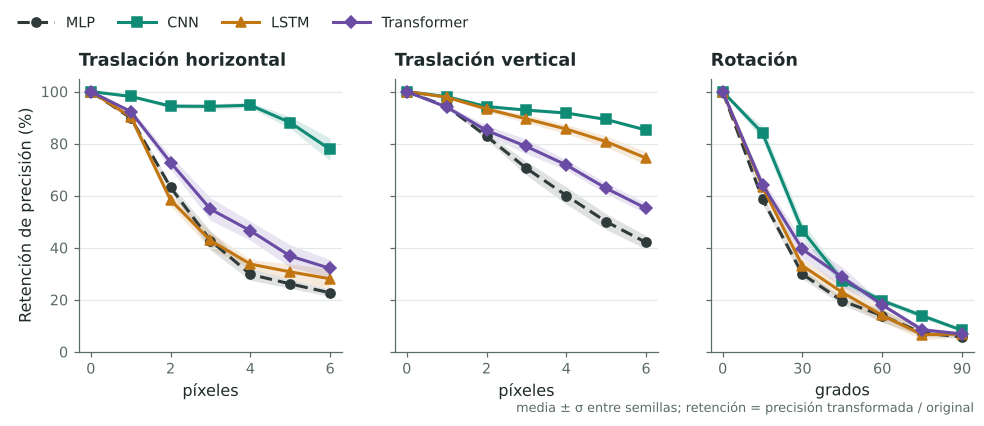

,MLP,CNN,LSTM,Transformer
"retención (%), 4 px y 45°, media ± σ",,,,
rotación 45°,"19,5 ± 1,4","27,3 ± 1,9","22,8 ± 3,0","28,7 ± 3,9"
horizontal 4 px,"29,7 ± 2,3","94,7 ± 1,1","33,7 ± 1,8","46,5 ± 3,6"
vertical 4 px,"60,1 ± 3,3","91,8 ± 0,5","85,6 ± 1,8","71,8 ± 1,9"


,transformación,modelo − MLP (retención),diferencia (puntos),IC 95 %,p
0,horizontal 4 px,CNN,"64,99","[62,23, 67,76]","< 0,001"
1,horizontal 4 px,LSTM,"3,96","[0,97, 6,96]","0,016"
2,horizontal 4 px,Transformer,"16,78","[12,21, 21,35]","< 0,001"
3,vertical 4 px,CNN,"31,72","[27,62, 35,82]","< 0,001"
4,vertical 4 px,LSTM,"25,54","[21,44, 29,63]","< 0,001"
5,vertical 4 px,Transformer,"11,74","[7,60, 15,87]","< 0,001"
6,rotación 45°,CNN,"7,80","[5,29, 10,30]","< 0,001"
7,rotación 45°,LSTM,"3,32","[−0,37, 7,00]","0,069"
8,rotación 45°,Transformer,"9,17","[4,35, 13,99]","0,004"


,MLP,CNN,LSTM,Transformer
retención descontando el azar (%),,,,
rotación 45°,"9,3 ± 1,6","18,4 ± 2,2","13,2 ± 3,4","19,6 ± 4,5"
horizontal 4 px,"20,9 ± 2,5","94,1 ± 1,2","25,5 ± 2,0","39,7 ± 4,1"
vertical 4 px,"55,0 ± 3,7","90,8 ± 0,5","83,8 ± 2,0","68,2 ± 2,2"


,MLP,CNN,LSTM,Transformer
rotación (grados) · retención (%),,,,
0,"100,0 ± 0,0","100,0 ± 0,0","100,0 ± 0,0","100,0 ± 0,0"
15,"58,6 ± 1,8","84,0 ± 2,6","63,3 ± 1,2","64,2 ± 2,2"
30,"29,8 ± 1,8","46,6 ± 3,1","33,1 ± 2,6","39,4 ± 3,3"
45,"19,5 ± 1,4","27,3 ± 1,9","22,8 ± 3,0","28,7 ± 3,9"
60,"13,9 ± 2,5","19,7 ± 1,0","14,0 ± 2,5","18,0 ± 0,8"
75,"7,2 ± 1,1","13,9 ± 1,1","6,6 ± 1,9","8,5 ± 0,9"
90,"5,7 ± 0,4","8,3 ± 0,5","6,8 ± 1,3","6,8 ± 1,0"
180,"21,8 ± 0,9","35,8 ± 2,6","25,4 ± 0,9","32,7 ± 1,9"


In [22]:
if TRAIN:
    E.h3(data, store, models=ONLY_MODELS, seeds=ONLY_SEEDS)
h3 = store.rows("h3")
fig = Fg.h3(h3); Fg.save(fig, "h3"); plt.show()
sel = h3[((h3["kind"] != "rotation") & (h3.magnitude == 4)) | ((h3["kind"] == "rotation") & (h3.magnitude == 45))]
display(T.pm_table(sel, "kind", "model", "retention", index_name="retención (%), 4 px y 45°, media ± σ")
        .rename(index={"shift_h": "horizontal 4 px", "shift_v": "vertical 4 px", "rotation": "rotación 45°"}))
display(T.h3_tests(h3))           # retención frente al MLP con 4 píxeles y 45° (puntos, IC 95 % de Welch)
# Retención descontando el azar: (precisión − 0,1) / (precisión original − 0,1). 0 = azar, 1 = sin pérdida
sel = sel.assign(ret_azar=(sel.test_acc - 0.1) / (sel.test_acc / sel.retention - 0.1))
display(T.pm_table(sel, "kind", "model", "ret_azar", index_name="retención descontando el azar (%)")
        .rename(index={"shift_h": "horizontal 4 px", "shift_v": "vertical 4 px", "rotation": "rotación 45°"}))
display(T.pm_table(h3[h3["kind"] == "rotation"], "magnitude", "model", "retention", index_name="rotación (grados) · retención (%)"))

**Resultado: confirmada, con dos matices.** Retención media con 4 píxeles de traslación y 45° de rotación (diferencias frente al MLP en la tabla anterior):

| Modelo | Horizontal 4 px | Vertical 4 px | Rotación 45° |
|---|---|---|---|
| MLP | 29,7 % | 60,1 % | 19,5 % |
| CNN | 94,7 % | 91,8 % | 27,3 % |
| LSTM | 33,7 % | 85,6 % | 22,8 % |
| Transformer | 46,5 % | 71,8 % | 28,7 % |

- **La CNN tolera la traslación en las dos direcciones** (+65 y +32 puntos sobre el MLP), porque la convolución es equivariante y el global average pooling resume la posición. No es invariante del todo: en horizontal, a 5 y 6 píxeles baja al 88 y al 78 % (en vertical, al 89 y al 85 %), cuando la prenda empieza a salirse del marco y pesan el submuestreo del pooling y el relleno con ceros, que permiten aprender posiciones absolutas (Azulay y Weiss, 2019; Kayhan y van Gemert, 2020).
- **La LSTM tolera la traslación vertical y no la horizontal**, tal como predice su sesgo: un desplazamiento vertical es un retraso de la secuencia de filas, que procesa con los mismos pesos en cada paso; uno horizontal cambia qué píxel entra en cada unidad, y ahí apenas mejora al MLP (+4 puntos, IC [1, 7]).
- **El Transformer tolera en parte** (+17 y +12 sobre el MLP), cuando habíamos previsto que no toleraría (tabla de predicciones de arriba). Aplica el mismo embedding a todos los parches, que es una forma débil de compartir pesos, pero sus posiciones son absolutas. Tampoco aprovecha que 4 píxeles muevan parches enteros: con 2 píxeles retiene el 72,7 % y con 4 el 46,5 %.
- **La traslación vertical perjudica menos a todos salvo a la CNN**, incluido el MLP (60 % frente a 30 % en horizontal), porque las prendas ocupan casi todo el alto de la imagen. La CNN retiene algo más en horizontal hasta 4 píxeles (94,7 frente a 91,8 %). Por eso cada modelo se compara con el MLP en la misma dirección.
- **Rotación: ninguna arquitectura la tolera.** A 45° todas retienen menos del 30 %; la CNN aguanta algo mejor los giros pequeños (84 % a 15°, frente al 59 % del MLP), que se parecen a deformaciones locales. A 180° la retención sube al 22-36 % porque bolsos, pantalones y vestidos son casi simétricos.

Descontando el azar (tercera tabla), las conclusiones no cambian: la CNN retiene el 94 y el 91 % con 4 píxeles, el MLP el 21 y el 55 %, y a 45° todos quedan por debajo del 20 %. Todos salvo la CNN retienen más en vertical, así que cada uno se compara con el MLP en la misma dirección.

La sección 8 (E2) lo comprueba en las explicaciones: en la CNN el mapa de Integrated Gradients se desplaza con la prenda, en la LSTM solo en vertical, y en el MLP y el Transformer no.

## 7. H4 · Memorización

> «Las cuatro arquitecturas pueden memorizar etiquetas aleatorias, pero no al mismo ritmo.»

Subconjunto estratificado de 5 000 imágenes. Sustituimos el 0, 25, 50 o 100 % de las etiquetas por una clase uniforme al azar, que coincide con la real un 10 % de las veces (como en Zhang et al., 2017). Las etiquetas aleatorias se sortean una vez (semilla 12) y son las mismas en las cinco semillas de entrenamiento. Entrenamos con el learning rate de cada modelo, constante, sin warmup y sin early stopping, hasta 300 épocas; solo paramos antes si el train llega al 99,9 %, es decir, cuando ya ha memorizado. Cada época medimos la precisión en train sobre las etiquetas usadas para entrenar; la de test, sobre las etiquetas reales, cada época hasta la 20 (donde se espera el pico) y después cada 5, para no multiplicar el coste. Por eso el test «final» de cada ejecución corresponde a la época en que paró.

**Tiempo hasta memorizar:** primera época en que el train supera el 50, el 80 y el 95 %, y los segundos hasta entonces. Si no se alcanza en 300 épocas, la ejecución se marca como no alcanzada. Los segundos son orientativos: se midieron en un Mac con tres entrenamientos en paralelo.

**Regularización:** weight decay de AdamW 0 frente a 0,1, igual para los cuatro modelos.

**Predicción (escrita antes de los experimentos):** con 100 % de ruido el test queda en el azar (≈10 %) aunque el train suba. El tiempo hasta memorizar crece con el ruido. Con ruido parcial, el test sube primero y baja después, porque las redes aprenden antes los patrones reales que el ruido (Arpit et al., 2017). Sobre el ritmo: ningún modelo con sesgo memoriza antes que el MLP, porque su sesgo encaja con las etiquetas reales y no con las aleatorias, y el MLP no tiene ninguna estructura que le estorbe.

,modelo,weight decay,etiquetas al azar,épocas hasta el umbral,semillas que llegan,segundos hasta el umbral,test al parar (%),pico de test (%)
0,MLP,"0,0",0 %,17 ± 1,5/5,4,"84,8","84,8"
1,MLP,"0,0",25 %,64 ± 2,5/5,17,"71,6","81,3"
2,MLP,"0,0",50 %,85 ± 6,5/5,20,"51,8","78,7"
3,MLP,"0,0",100 %,no llega,0/5,—,"10,1","15,5"
4,MLP,"0,1",0 %,18 ± 2,5/5,4,"84,7","84,9"
5,MLP,"0,1",25 %,77 ± 2,5/5,19,"71,9","81,4"
6,MLP,"0,1",50 %,121 ± 7,5/5,30,"50,7","78,6"
7,MLP,"0,1",100 %,no llega,0/5,—,"10,4","15,4"
8,CNN,"0,0",0 %,32 ± 3,5/5,19,"86,2","86,2"
9,CNN,"0,0",25 %,93 ± 10,5/5,100,"71,4","78,1"


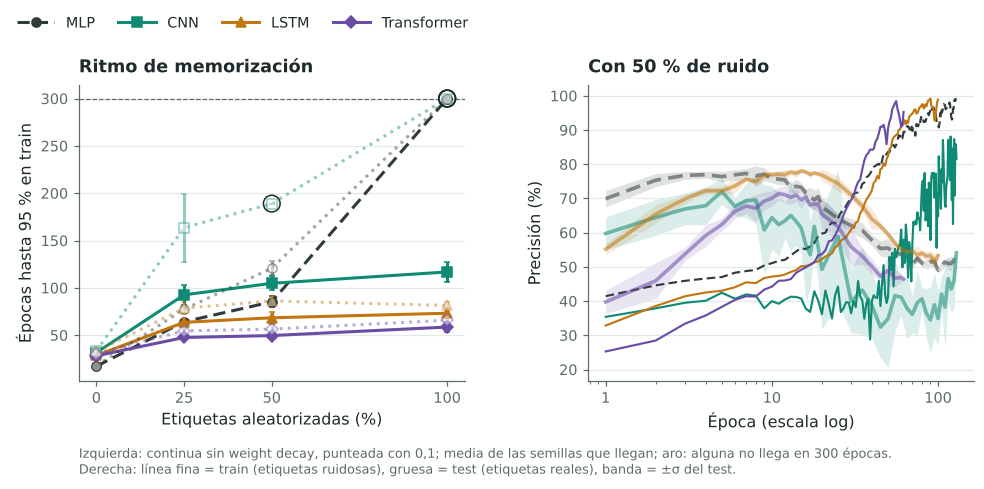

,MLP,CNN,LSTM,Transformer
"weight decay · oscilación media de la precisión de train entre épocas (puntos), 50 % al azar",,,,
0.0,"1,4 ± 0,1","14,0 ± 1,3","1,4 ± 0,2","2,2 ± 0,3"
0.1,"1,9 ± 0,1","15,3 ± 0,8","1,7 ± 0,2","2,0 ± 0,3"


In [23]:
if TRAIN:
    E.h4(data, store, models=ONLY_MODELS, seeds=ONLY_SEEDS)
h4s, h4c = store.rows("h4"), store.rows("h4curves")
display(T.h4_table(h4s, "epoch_95"))   # épocas hasta el 95 % de train (media ± σ de las semillas que llegan)
fig = Fg.h4(h4s, h4c); Fg.save(fig, "h4"); plt.show()
# oscilación de la precisión de train entre épocas consecutivas (media de |Δ| tras la época 20), con 50 % de ruido
c50 = h4c[(h4c.label_noise == 0.5)].sort_values("epoch")
osc = c50.groupby(["model", "weight_decay", "seed"]).train_acc.apply(lambda s: s.diff().abs().iloc[20:].mean()).reset_index()
display(T.pm_table(osc, "weight_decay", "model", "train_acc",
                   index_name="weight decay · oscilación media de la precisión de train entre épocas (puntos), 50 % al azar"))

**Resultado: confirmada.** Las cuatro arquitecturas memorizan etiquetas totalmente aleatorias y lo hacen a ritmos muy distintos. El MLP necesita un learning rate menor que el del protocolo para conseguirlo (control al final de esta sección).

Épocas hasta superar el 95 % de precisión en train, sin weight decay (media de 5 semillas; tabla completa con σ arriba). El «pico de test» de la tabla es descriptivo: se elige mirando el test, así que no es una estimación de generalización.

| Etiquetas aleatorias | MLP | CNN | LSTM | Transformer |
|---|---|---|---|---|
| 0 % | 17 | 32 | 29 | 28 |
| 25 % | 64 | 93 | 64 | 48 |
| 50 % | 85 | 105 | 68 | 50 |
| 100 % | no llega (0/5); 110 con lr 10⁻³ | 117 | 73 | 59 |

- **Se cumplen las tres predicciones sobre el test.** Con el 100 % de etiquetas aleatorias el test termina en el azar (entre el 10,1 y el 10,4 %) aunque el train llegue al 100 % (en el MLP, con el learning rate del protocolo, al 81 %). Sin weight decay, el tiempo hasta memorizar crece con el ruido en todos los modelos. Y con ruido parcial el test sube primero y baja después: con el 50 % de ruido, el máximo y el valor final son 78,7 y 51,8 % en el MLP, 74,6 y 53,4 % en la CNN, 78,5 y 53,7 % en la LSTM y 72,6 y 47,6 % en el Transformer. Las redes aprenden antes los patrones reales que el ruido (Arpit et al., 2017).
- **El sesgo inductivo no protege contra la memorización.** La CNN, la LSTM y el Transformer memorizan el 100 % de etiquetas aleatorias en 117, 73 y 59 épocas, como en Zhang et al. (2017). Con etiquetas ruidosas, el Transformer es el más rápido en llegar al 95 %.
- **El MLP no llega con el learning rate del protocolo, pero sí con uno menor.** Con 3·10⁻³ se estanca en torno al 81 % de train (entre el 70 y el 88 % según la semilla). Tiene parámetros de sobra (101 706 para 5 000 imágenes), así que sospechábamos de la optimización, y el control lo confirma: con 10⁻³ memoriza en 110 ± 6 épocas y con 3·10⁻⁴ en 148 ± 5, las cinco semillas. 3·10⁻³ se eligió con etiquetas limpias, donde el MLP es el más rápido de los cuatro (17 épocas); con etiquetas aleatorias es demasiado alto para ajustar los últimos ejemplos.
- **El weight decay retrasa la memorización, pero no la impide ni mejora el test.** Con 0,1 y 50 % de ruido, el MLP pasa de 85 a 121 épocas, la LSTM de 68 a 86 y el Transformer de 50 a 56, y el máximo en test cambia menos de un punto (con weight decay, la LSTM tarda algo más con el 50 % de ruido que con el 100 %: 86 frente a 81 épocas). Coincide con Zhang et al. (2017): la regularización explícita no es lo que explica la generalización.
- **La CNN es la excepción con weight decay, y por un motivo de medida y optimización.** Con 0,1 no llega al 95 % con el 50 % de ruido (1 de 5 semillas) ni con el 100 % (0 de 5). Su precisión de train, medida en modo evaluación, oscila 13-15 puntos de una época a la siguiente en todas las condiciones con ruido, también sin weight decay, frente a 1-2,5 puntos en el resto (tabla de arriba). Es la única con BatchNorm, y el control lo explica: medida durante el entrenamiento, con las estadísticas de cada lote, la oscilación baja a unos 2 puntos, como en los demás. Es decir, la red aprende de forma estable, pero las estadísticas acumuladas de BatchNorm que usa la evaluación van por detrás de unos pesos que cambian mucho con un learning rate alto. Con weight decay se agrava, porque con BatchNorm encoger los pesos sube el learning rate efectivo (van Laarhoven, 2017).

Respecto a la predicción previa sobre el ritmo (ningún modelo con sesgo memorizaría antes que el MLP): falla. El Transformer es más rápido que el MLP con cualquier nivel de ruido; la LSTM, con el 50 y el 100 % (con el 25 % empatan: 64 frente a 64 épocas); y la CNN es más lenta con ruido parcial y más rápida con etiquetas totalmente aleatorias. Con el mismo learning rate para todos (10⁻³, control siguiente) el orden con el 100 % de ruido es Transformer (59 épocas), LSTM (81), MLP (110) y CNN (199): la predicción falla para el Transformer y la LSTM y se cumple para la CNN.

**Controles: ¿es la arquitectura o el learning rate?** Tras ver los resultados repetimos algunas configuraciones con otro learning rate constante, sin cambiar nada más. Se ejecutaron en CPU con `python -m sesgos.run extra`; la fila «protocolo» es la ejecución principal. El MLP con 3·10⁻³ se repitió también en CPU para comprobar que el dispositivo no cambia la conclusión.

In [24]:
if TRAIN:
    E.h4_control(data, store)
ctl = store.rows("h4ctl")
if len(ctl):
    display(T.h4_control_table(ctl, h4s))
    cc = store.rows("h4ctlcurves")
    q = cc[(cc.model == "cnn") & (cc.label_noise == 0.5) & np.isclose(cc.lr, 3e-3)].sort_values("epoch")
    if len(q) and "train_acc_batch" in q:
        osc = q.groupby("seed").apply(lambda g: pd.Series({
            "medida en evaluación": g.train_acc.diff().abs().iloc[20:].mean() * 100,
            "medida durante el entrenamiento": g.train_acc_batch.diff().abs().iloc[20:].mean() * 100}))
        display(osc.agg(["mean", "std"]).T.map(lambda v: f"{v:.1f}".replace(".", ",")).rename(columns={"mean": "media", "std": "σ"})
                .rename_axis("CNN, 50 % al azar · oscilación de la precisión de train entre épocas (puntos)"))
else:
    print("Sin controles en results/raw (h4ctl).")

,modelo,etiquetas al azar,weight decay,learning rate,origen,épocas hasta el umbral,semillas que llegan,train al parar (%),test al parar (%)
0,MLP,100 %,"0,0",3e-4,control (cpu),148 ± 5,5/5,"99,9","10,4"
1,MLP,100 %,"0,0",1e-3,control (cpu),110 ± 6,5/5,"99,9","9,9"
2,MLP,100 %,"0,0",3e-3,control (cpu),250,1/5,"84,6","10,0"
3,MLP,100 %,"0,0",3e-3,protocolo (mps),no llega,0/5,"80,8","10,1"
4,CNN,50 %,"0,0",3e-3,control (cpu),100 ± 5,3/3,"99,9","54,0"
5,CNN,50 %,"0,0",3e-3,protocolo (mps),105 ± 7,5/5,"100,0","53,4"
6,CNN,100 %,"0,0",1e-3,control (cpu),199 ± 28,3/3,"95,7","10,0"
7,CNN,100 %,"0,0",3e-3,protocolo (mps),117 ± 11,5/5,"100,0","10,4"
8,LSTM,100 %,"0,0",1e-3,control (cpu),81 ± 3,3/3,"99,9","9,9"
9,LSTM,100 %,"0,0",3e-3,protocolo (mps),73 ± 5,5/5,"99,9","10,4"


,media,σ
"CNN, 50 % al azar · oscilación de la precisión de train entre épocas (puntos)",,
medida en evaluación,"13,5","3,2"
medida durante el entrenamiento,"2,0","0,0"


**Resultado de los controles.**

- **MLP:** con 10⁻³ memoriza el 100 % de etiquetas aleatorias en 110 ± 6 épocas y con 3·10⁻⁴ en 148 ± 5, las cinco semillas. Con 3·10⁻³, repetido en CPU, 1 de 5 semillas llega (en la época 250) y el resto se queda entre el 71 y el 92 %: el dispositivo no cambia la conclusión. El estancamiento era del learning rate, no de la arquitectura.
- **LSTM y CNN con 10⁻³ (3 semillas):** la LSTM memoriza en 81 épocas (73 con 3·10⁻³) y la CNN en 199 ± 28 (117 con 3·10⁻³). Con el mismo learning rate para los cuatro, el orden es Transformer (59), LSTM (81), MLP (110) y CNN (199). El ritmo depende de la arquitectura, y la diferencia entre la más rápida y la más lenta se agranda: de 2 a más de 3 veces.
- **CNN, oscilación:** con el 50 % de ruido, la precisión de train medida en evaluación salta 13,5 puntos de media entre épocas (3 semillas) y medida durante el entrenamiento, 2,0, como los demás modelos. La oscilación es de la medida con las estadísticas acumuladas de BatchNorm, no del aprendizaje. (La medida durante el entrenamiento promedia toda la época, así que es algo más suave por construcción; aun así, la diferencia es de casi siete veces.)

## 8. Explicabilidad

**E1. Pesos de la primera capa (H1).** Filtros 3×3 de la CNN entrenada con imágenes originales y con píxeles permutados. Y filas de la primera capa del MLP: original, y entrenado con píxeles permutados después de deshacer la permutación. Si el MLP es invariante, sus plantillas deben parecerse; la CNN permutada no debería tener filtros con estructura espacial. Para no depender de la vista, lo medimos con la correlación entre pesos vecinos (horizontal y vertical) de la primera capa, en las cinco semillas: alta si los pesos varían suavemente en el espacio, cerca de 0 si no hay estructura.

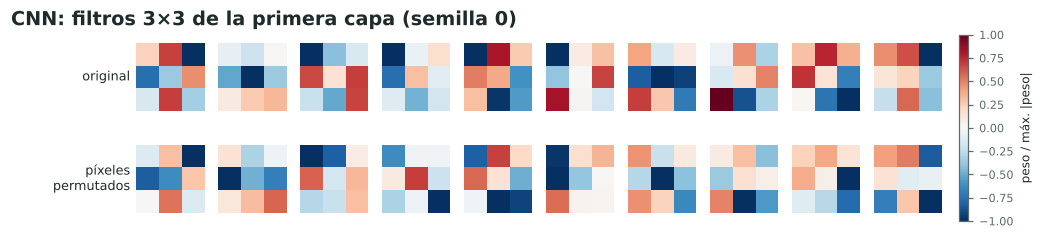

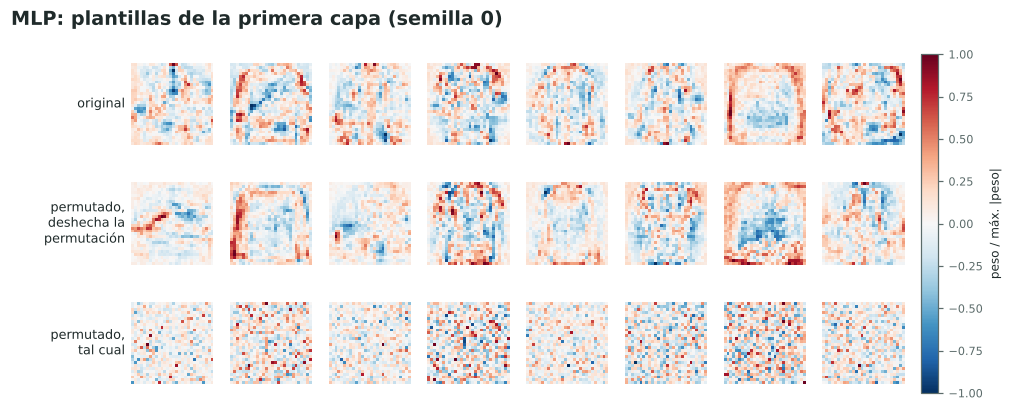

,MLP,CNN
"correlación entre pesos vecinos, media ± σ (5 semillas; MLP permutado: deshecha la permutación)",,
original,"0,559 ± 0,006","0,063 ± 0,059"
bloques,—,"0,017 ± 0,059"
pixeles,"0,557 ± 0,006","−0,087 ± 0,034"


In [25]:
def have(*pairs):
    ok = all(os.path.exists(store.ckpt(m, c, 0)) for m, c in pairs)
    if not ok:
        print("Faltan checkpoints para esta figura:", pairs)
    return ok

def load(model, cond, seed=0):
    m = build(model).to(DEVICE)
    m.load_state_dict(torch.load(store.ckpt(model, cond, seed), map_location=DEVICE))
    return m.eval()

perm = pixel_permutation(C.PERM_SEED)
inv = torch.argsort(perm)
if have(("cnn", "original"), ("cnn", "pixeles")):
    f = [X.first_layer_images(load("cnn", c), "cnn").cpu().numpy()[:10] for c in ["original", "pixeles"]]
    fig = Fg.image_grid([*f[0], *f[1]], 2, 10, title="CNN: filtros 3×3 de la primera capa (semilla 0)",
                        row_labels=["original", "píxeles\npermutados"], cbar_label="peso / máx. |peso|")
    Fg.save(fig, "e1_cnn"); plt.show()
if have(("mlp", "original"), ("mlp", "pixeles")):
    w0 = X.first_layer_images(load("mlp", "original"), "mlp").cpu().numpy()
    wp = X.first_layer_images(load("mlp", "pixeles"), "mlp", inverse_perm=inv.to(DEVICE)).cpu().numpy()
    wr = X.first_layer_images(load("mlp", "pixeles"), "mlp").cpu().numpy()
    fig = Fg.image_grid(list(w0[:8]) + list(wp[:8]) + list(wr[:8]), 3, 8, figsize=(9.5, 4.0),
                        title="MLP: plantillas de la primera capa (semilla 0)",
                        row_labels=["original", "permutado,\ndeshecha la\npermutación", "permutado,\ntal cual"],
                        cbar_label="peso / máx. |peso|")
    Fg.save(fig, "e1_mlp"); plt.show()
# Medida: correlación entre pesos vecinos de la primera capa, con todas las semillas cuyos checkpoints haya
E.e1_smoothness(data, store)
e1 = store.rows("e1")
e1v = e1.assign(corr=lambda d: d.neighbor_corr_despermutado.fillna(d.neighbor_corr))
display(T.pm_table(e1v, "condition", "model", "corr", scale=1, dec=3,
                   index_name="correlación entre pesos vecinos, media ± σ (5 semillas; MLP permutado: deshecha la permutación)")
        .reindex(["original", "bloques", "pixeles"]).fillna("—"))

**Resultado.** Las figuras son de la semilla 0 y se leen de forma cualitativa; la medida usa las cinco. Las plantillas del MLP son igual de suaves con y sin permutación, una vez deshecha: la correlación entre pesos vecinos es 0,559 ± 0,006 en el original y 0,557 ± 0,006 en el permutado y des-permutado (0,001 sin deshacer la permutación). Es la versión en los pesos del resultado de H1: el MLP aprende lo mismo, en otro orden. En la CNN la diferencia va en la dirección esperada pero es pequeña: 0,06 ± 0,06 en el original frente a −0,09 ± 0,03 con píxeles permutados (diferencia −0,15, IC 95 % [−0,22, −0,08]) y 0,02 con bloques. Con filtros de 3×3 seguidos de BatchNorm, la primera capa de la CNN no muestra detectores de bordes nítidos a simple vista, así que la figura de sus filtros, por sí sola, no es concluyente.

**E2. ¿Se mueve la explicación con la prenda? (H3).** Integrated Gradients (Sundararajan et al., 2017) con la imagen en negro como referencia. Primero, una prenda sin desplazar y desplazada 4 píxeles a la derecha en los cuatro modelos. Después, la medida: para 300 imágenes de test, la correlación entre el mapa de la imagen desplazada *k* píxeles y el mapa original desplazado *k* píxeles. Vale 1 si la explicación se mueve exactamente con la prenda y 0 si no tiene nada que ver.

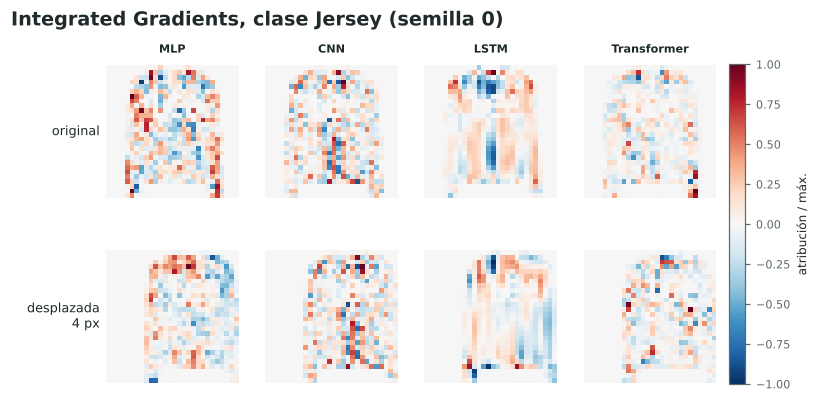

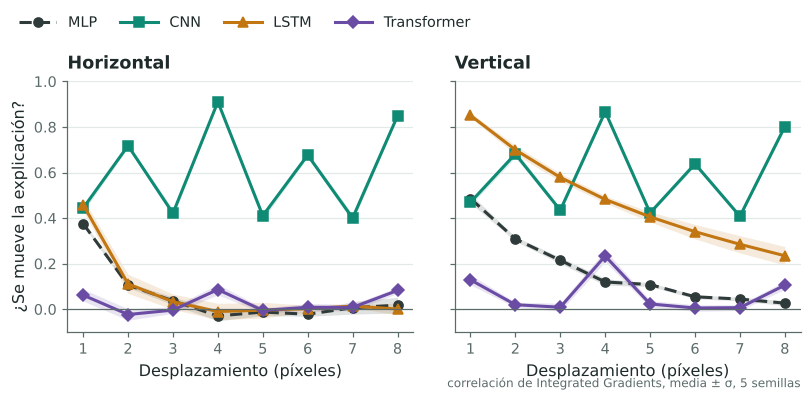

,MLP,CNN,LSTM,Transformer
"desplazamiento horizontal (px) · correlación, media ± σ",,,,
1,"0,38 ± 0,01","0,44 ± 0,02","0,46 ± 0,03","0,06 ± 0,03"
2,"0,11 ± 0,01","0,72 ± 0,01","0,11 ± 0,04","−0,02 ± 0,03"
3,"0,04 ± 0,02","0,42 ± 0,02","0,03 ± 0,03","−0,00 ± 0,01"
4,"−0,03 ± 0,02","0,91 ± 0,00","−0,01 ± 0,04","0,09 ± 0,02"
5,"−0,01 ± 0,02","0,41 ± 0,02","−0,00 ± 0,03","−0,01 ± 0,01"
6,"−0,02 ± 0,01","0,68 ± 0,01","0,00 ± 0,02","0,01 ± 0,02"
7,"0,01 ± 0,03","0,40 ± 0,02","0,01 ± 0,01","0,01 ± 0,01"
8,"0,02 ± 0,03","0,85 ± 0,01","0,00 ± 0,03","0,08 ± 0,01"


,MLP,CNN,LSTM,Transformer
"desplazamiento vertical (px) · correlación, media ± σ",,,,
1,"0,49 ± 0,02","0,47 ± 0,01","0,85 ± 0,01","0,13 ± 0,02"
2,"0,31 ± 0,01","0,68 ± 0,02","0,70 ± 0,02","0,02 ± 0,01"
3,"0,21 ± 0,01","0,43 ± 0,01","0,58 ± 0,02","0,01 ± 0,02"
4,"0,12 ± 0,01","0,87 ± 0,01","0,48 ± 0,02","0,23 ± 0,03"
5,"0,11 ± 0,01","0,42 ± 0,01","0,41 ± 0,02","0,02 ± 0,01"
6,"0,05 ± 0,01","0,64 ± 0,01","0,34 ± 0,03","0,01 ± 0,01"
7,"0,04 ± 0,01","0,41 ± 0,01","0,28 ± 0,04","0,01 ± 0,01"
8,"0,03 ± 0,01","0,80 ± 0,01","0,23 ± 0,04","0,11 ± 0,02"


In [26]:
i = 1                                          # la misma prenda que en el póster
x = data.Xte[i:i + 1]; y = data.Yte[i:i + 1]
names = [m for m in C.MODELS if have((m, "original"))]
maps = {k: [] for k in [0, 4]}
for m_name in names:
    m = load(m_name, "original")
    for k in [0, 4]:
        xi = data.norm(shift(x, dx=k))
        maps[k].append(X.integrated_gradients(m, xi, y, data.norm(torch.zeros_like(x)))[0].cpu().numpy())
fig = Fg.image_grid(maps[0] + maps[4], 2, len(names), ax_titles=[C.MODEL_LABELS[n] for n in names] + [""] * len(names),
                    figsize=(7.5, 4.0), row_labels=["original", "desplazada\n4 px"], cbar_label="atribución / máx.",
                    title=f"Integrated Gradients, clase {CLASSES[int(y)]} (semilla 0)")
Fg.save(fig, "e2_saliency"); plt.show()
E.e2_equivariance(data, store)
e2 = store.rows("e2")
fig = Fg.e2(e2); Fg.save(fig, "e2_equivarianza"); plt.show()
for d in ["horizontal", "vertical"]:
    display(T.pm_table(e2[e2.direction == d], "shift", "model", "corr", scale=1, dec=2,
                       index_name=f"desplazamiento {d} (px) · correlación, media ± σ"))

**Resultado.** La explicación de la CNN se desplaza con la prenda y la de los demás modelos no, como predice H3:

- **CNN:** 0,91 con 4 píxeles en horizontal y 0,87 en vertical. La curva tiene forma de sierra: en torno a 0,4 con desplazamientos impares, 0,7 con múltiplos de 2 y entre 0,80 y 0,91 con múltiplos de 4. Es la huella de sus dos max-pool de 2×2: la red solo es equivariante a desplazamientos múltiplos de su paso acumulado, que es 4 (Azulay y Weiss, 2019).
- **LSTM:** se mueve en vertical (0,85 con 1 píxel y 0,48 con 4) y no en horizontal (−0,01 con 4), porque un desplazamiento vertical es un retraso de la secuencia de filas.
- **Transformer:** casi 0 en las dos direcciones, con un pequeño repunte con 4 y 8 píxeles (0,09 y 0,08 en horizontal; 0,23 y 0,11 en vertical), cuando el desplazamiento mueve parches enteros. Sus posiciones son absolutas.
- **MLP:** 0,38 y 0,49 con 1 píxel, solo porque los mapas son algo suaves, y 0,12 o menos a partir de 4 píxeles.

La tabla de H3 y esta medida apuntan en la misma dirección: el modelo que conserva la precisión al desplazar la prenda es también el que desplaza su explicación con ella. Es una coincidencia entre medidas, no una prueba de que la explicación cause la tolerancia; la LSTM, por ejemplo, retiene el 86 % en vertical con una explicación que se mueve a medias (0,48).

**E3. Atención del Transformer.** Atención del token CLS sobre los 49 parches en el último bloque, en imágenes originales y con los bloques permutados (deshaciendo la permutación para compararlas).

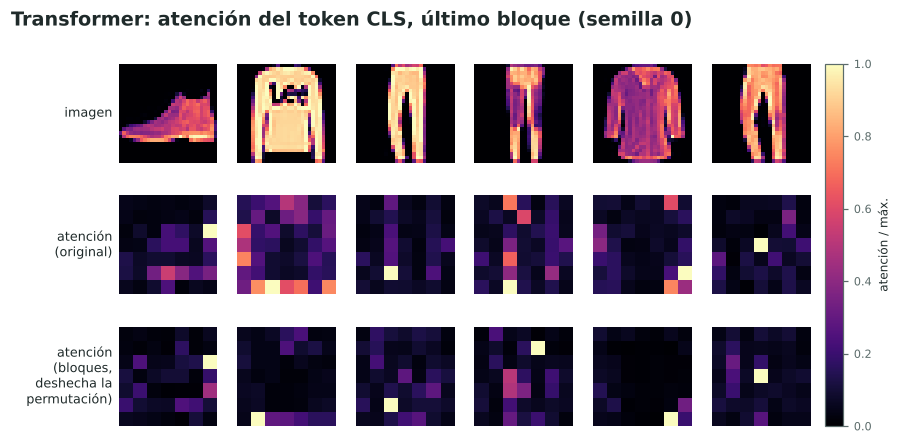

In [27]:
if have(("vit", "original"), ("vit", "bloques")):
  v = load("vit", "original")
  bperm, order = block_permutation(C.PERM_SEED)
  xs = data.Xte[:6]
  a0 = X.vit_cls_attention(v, data.norm(xs))[-1].cpu()
  vb = load("vit", "bloques")
  ab = X.vit_cls_attention(vb, data.norm(apply_perm(xs, bperm)))[-1].cpu().reshape(-1, 49)
  ab = ab[:, torch.argsort(order)].reshape(-1, 7, 7)
  fig = Fg.image_grid([*xs[:, 0].cpu().numpy(), *a0.numpy(), *ab.numpy()], 3, 6, cmap="magma", symmetric=False,
                      figsize=(8.5, 4.4), title="Transformer: atención del token CLS, último bloque (semilla 0)",
                      row_labels=["imagen", "atención\n(original)", "atención\n(bloques,\ndeshecha la\npermutación)"],
                      cbar_label="atención / máx.")
  Fg.save(fig, "e3_attention"); plt.show()

**Observación (cualitativa, semilla 0).** En el último bloque, el token CLS atiende a pocos parches, sobre todo en los bordes de la prenda. Con los bloques permutados y la permutación deshecha, la atención también cae sobre parches de la prenda, pero no en los mismos: son dos modelos entrenados por separado, con precisión parecida (88,1 y 88,6 % en esta semilla). Es coherente con el control exacto de H1, según el cual permutar bloques equivale a permutar posiciones, pero no lo demuestra: la prueba es ese control, no esta figura.

## 9. Conclusiones

**Un sesgo inductivo ayuda cuando los datos tienen la estructura que el sesgo supone, y puede perjudicar cuando no la tienen.** La CNN es la mejor con imágenes reales y queda por debajo del MLP con los píxeles desordenados; tolera desplazamientos porque la convolución los respeta y no tolera giros porque nada en ella los respeta.

| Hipótesis | Veredicto | Por qué |
|---|---|---|
| H1 · Estructura de la entrada | Confirmada | Con los píxeles permutados la CNN pierde 3,9 puntos y la LSTM 2,8, y el MLP no cambia. El Transformer solo cae con píxeles: permutar bloques equivale a permutar sus posiciones, que vuelve a aprender. |
| H2 · Cantidad de datos | Confirmada, con matiz | Con 100 imágenes el mejor y el peor modelo se separan 18,6 puntos (3,6 con 55 000), pero porque la LSTM y el Transformer se hunden. La CNN no supera al MLP con 100 imágenes (tampoco cambiando el subconjunto), empieza a superarlo entre 300 y 1 000 y su ventaja crece con los datos. |
| H3 · Transformaciones en test | Confirmada | Desplazada 4 píxeles, la CNN retiene el 95 y el 92 % de su precisión, frente al 30 y el 60 % del MLP. La LSTM solo tolera el desplazamiento vertical. Ninguna tolera la rotación. |
| H4 · Memorización | Confirmada | Las cuatro memorizan etiquetas totalmente aleatorias con el test en el azar, a ritmos muy distintos: 59 épocas el Transformer, 73 la LSTM, 117 la CNN y 110 el MLP (este, con learning rate 10⁻³; con el del protocolo se estanca). Con 10⁻³ para todos, el orden es Transformer, LSTM, MLP y CNN. El weight decay retrasa la memorización sin mejorar el test. |

**Límites del estudio.**

- Un solo conjunto de datos, con prendas centradas y escaladas, y modelos de unos 100 000 parámetros: no sabemos si las conclusiones se mantienen con imágenes menos regulares o con modelos más grandes.
- El learning rate se eligió una vez por modelo, con todos los datos, en la rejilla {3·10⁻⁴, 10⁻³, 3·10⁻³}: 3·10⁻³ para el MLP, la CNN y la LSTM, que es el extremo de la rejilla, y 10⁻³ para el Transformer. Un control con 10⁻² no mejora al MLP (89,4 % en validación frente a 90,4 %) ni a la LSTM (91,2 frente a 91,3 %), pero sí a la CNN (93,6 frente a 92,9 %, una semilla): su ventaja sobre el MLP está, si acaso, subestimada. Se mantiene en H2 y en H4; el estancamiento del MLP con etiquetas aleatorias venía de ese learning rate (controles de H4).
- Una sola técnica de regularización (weight decay) con una sola intensidad (0,1).
- En H2 el subconjunto de cada tamaño es el mismo en todas las semillas; el control con otro subconjunto por semilla mantiene la conclusión con 100 imágenes y retrasa el cruce de la CNN con el MLP.
- Cinco semillas por condición y muchas comparaciones: las diferencias pequeñas con p cercano a 0,05 no deben leerse como efectos. Las caídas de H1, la tolerancia de H3 y el ritmo de memorización de H4 tienen p < 0,001; la desventaja de la CNN frente al MLP con 100 imágenes es más débil (p = 0,016 con el subconjunto del protocolo y 0,038 emparejada con otros subconjuntos), y por eso se apoya en los dos.

Las predicciones se escribieron antes de los experimentos y no se han cambiado. Los veredictos de la figura siguiente usan los criterios escritos en `verdicts.py`.

La figura siguiente responde una pregunta por hipótesis para cada modelo (sí, en parte o no): círculo hueco para lo predicho antes de los experimentos y relleno para lo observado. El MLP es la referencia en H2 y H4, así que esas celdas quedan vacías.

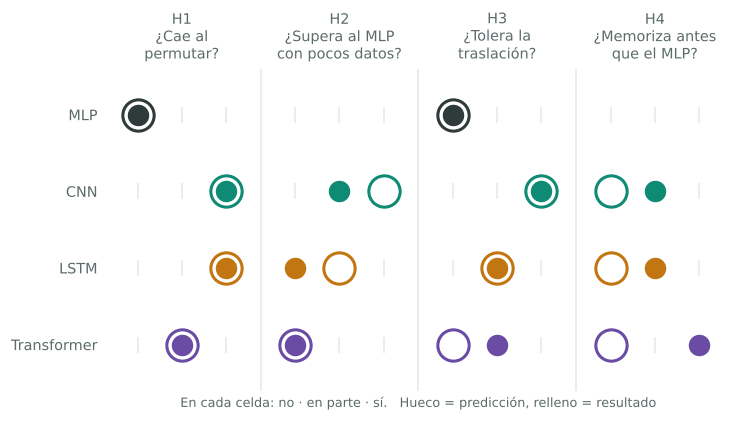

In [28]:
from sesgos.verdicts import PRED, OBS      # PRED es la predicción previa; OBS se rellena en sesgos/verdicts.py
fig = Fg.verdict_matrix(PRED, OBS); Fg.save(fig, "veredictos"); plt.show()

## 10. Figuras para el póster

Las mismas figuras con letra a escala de póster, exportadas al ancho exacto de su hueco en el A0, en PDF vectorial (`figures/poster/`). También se pueden generar fuera del notebook con `python tools/make_figures.py --results <carpeta>`.

In [29]:
print(Fg.all_figures(RESULTS, "figures"))

['h1', 'h2', 'h3', 'h4', 'e2_equivarianza', 'veredictos', 'poster/h1', 'poster/h2', 'poster/h3', 'poster/h4', 'poster/e2_equivarianza', 'poster/veredictos']


## Referencias

- Xiao, Rasul y Vollgraf (2017). Fashion-MNIST: a Novel Image Dataset for Benchmarking Machine Learning Algorithms. arXiv:1708.07747.
- Zhang, Bengio, Hardt, Recht y Vinyals (2017). Understanding deep learning requires rethinking generalization. ICLR.
- Arpit et al. (2017). A Closer Look at Memorization in Deep Networks. ICML.
- Azulay y Weiss (2019). Why do deep convolutional networks generalize so poorly to small image transformations? JMLR 20.
- Kayhan y van Gemert (2020). On Translation Invariance in CNNs: Convolutional Layers Can Exploit Absolute Spatial Location. CVPR.
- Dosovitskiy et al. (2021). An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale. ICLR.
- Sundararajan, Taly y Yan (2017). Axiomatic Attribution for Deep Networks. ICML.
- van Laarhoven (2017). L2 Regularization versus Batch and Weight Normalization. arXiv:1706.05350.